In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sreerammmmm/yelpchi/YelpChi.mat
/kaggle/input/datasets/sreerammmmm/yelp-dataset/Dataset_User_Agreement.pdf
/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_review.json
/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_checkin.json
/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_business.json
/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_tip.json
/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_user.json


# Trustline — AI-Based Fake Seller Detection and Consumer Awareness System

Trustline is an AI-based system designed to identify suspicious activity associated with e-commerce sellers.

The system analyzes available review information, reviewer behavior, review patterns, and similarity between reviews to estimate the risk associated with a seller.

The final system will generate a risk score and provide understandable reasons for the detected risk.

## Project Pipeline

YelpChi Dataset → Data Preparation → Feature Extraction → Model Training → Feature Fusion → Risk Score → Model Evaluation → Saved Model


In [3]:
# Trustline - Initial Environment Setup

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Trustline environment initialized successfully.")

Trustline environment initialized successfully.


## Step 1: Check the Kaggle Environment

Before loading the dataset, we first verify the Python environment and check whether the Kaggle GPU is available.

A GPU will be useful later when training the deep learning and NLP components of the project.

In [4]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.10.0+cu128
GPU available: True
GPU: Tesla T4


## Step 2: Locate the YelpChi Dataset

Before training the model, we need to locate the YelpChi dataset attached to this Kaggle notebook.

The dataset may contain review text, user information, business information, timestamps, ratings, and/or graph-based features.

We first inspect the available files so that we can identify the exact dataset format and file path before loading it.

In [5]:
import os

print("Files available in /kaggle/input:")

for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

Files available in /kaggle/input:
/kaggle/input/datasets/sreerammmmm/yelpchi/YelpChi.mat
/kaggle/input/datasets/sreerammmmm/yelp-dataset/Dataset_User_Agreement.pdf
/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_review.json
/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_checkin.json
/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_business.json
/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_tip.json
/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_user.json


## Step 3: Inspect the YelpChi Dataset

The YelpChi dataset is provided as a MATLAB `.mat` file.

Before loading the complete dataset into memory, we first inspect the internal variables stored inside the file. This allows us to identify the available features, labels, and network information safely without loading the entire dataset at once.

In [6]:
from scipy.io import whosmat

dataset_path = "/kaggle/input/datasets/sreerammmmm/yelpchi/YelpChi.mat"

print("Inspecting YelpChi.mat...")
print()

variables = whosmat(dataset_path)

print("Variables stored in YelpChi.mat:")
print("-" * 60)

for name, shape, data_type in variables:
    print(f"Name: {name}")
    print(f"Shape: {shape}")
    print(f"Type: {data_type}")
    print("-" * 60)

Inspecting YelpChi.mat...

Variables stored in YelpChi.mat:
------------------------------------------------------------
Name: homo
Shape: (45954, 45954)
Type: sparse
------------------------------------------------------------
Name: net_rur
Shape: (45954, 45954)
Type: sparse
------------------------------------------------------------
Name: net_rtr
Shape: (45954, 45954)
Type: sparse
------------------------------------------------------------
Name: net_rsr
Shape: (45954, 45954)
Type: sparse
------------------------------------------------------------
Name: features
Shape: (45954, 32)
Type: sparse
------------------------------------------------------------
Name: label
Shape: (1, 45954)
Type: int64
------------------------------------------------------------


## Step 4: Load the YelpChi Dataset

The YelpChi dataset contains 45,954 nodes with 32 numerical features and corresponding labels.

It also contains several sparse network representations that describe relationships between the nodes.

For the initial machine-learning pipeline, we will load the feature matrix and labels first. The network matrices will be handled separately when we implement the behavioral and similarity analysis components.

In [7]:
from scipy.io import loadmat

dataset_path = "/kaggle/input/datasets/sreerammmmm/yelpchi/YelpChi.mat"

data = loadmat(dataset_path)

print("Dataset loaded successfully.")
print()
print("Available components:")
print(data.keys())

Dataset loaded successfully.

Available components:
dict_keys(['__header__', '__version__', '__globals__', 'homo', 'net_rur', 'net_rtr', 'net_rsr', 'features', 'label'])


## Step 5: Extract Features and Labels

The YelpChi dataset contains a feature matrix and a corresponding label vector.

The feature matrix contains 32 features for each of the 45,954 samples.

The label vector contains one target label for each sample.

In supervised learning, the features are used as the model inputs, while the labels are used as the target values that the model learns to predict.

In [8]:
# Extract the feature matrix
features = data["features"]

# Extract the labels and convert them into a one-dimensional array
labels = data["label"].flatten()

print("Features shape:", features.shape)
print("Labels shape:", labels.shape)

Features shape: (45954, 32)
Labels shape: (45954,)


## Step 6: Examine the Target Labels

Before training the model, we need to understand the target labels.

We will identify the unique label values and count how many samples belong to each class.

This helps us understand the classification problem and check whether the dataset is balanced or imbalanced.

In [9]:
import numpy as np

# Make sure labels exists
if "labels" not in globals():
    labels = data["label"].flatten()

unique_labels, label_counts = np.unique(labels, return_counts=True)

print("Label distribution:")
print()

for label_value, count in zip(unique_labels, label_counts):
    print(f"Label {label_value}: {count} samples")

Label distribution:

Label 0: 39277 samples
Label 1: 6677 samples


## Step 7: Inspect the Feature Matrix

The YelpChi dataset contains 32 features for each sample.

Before training a model, we need to understand the structure of these features, including their data type, dimensions, and numerical values.

This step helps us determine what information is actually available to the machine-learning model.

In [10]:
print("Feature matrix type:", type(features))
print("Feature matrix shape:", features.shape)

# Convert the sparse matrix to CSR format for row access
features_csr = features.tocsr()

print("\nFirst 5 rows of the feature matrix:")
print(features_csr[:5].toarray())

Feature matrix type: <class 'scipy.sparse._coo.coo_matrix'>
Feature matrix shape: (45954, 32)

First 5 rows of the feature matrix:
[[0.02237555 0.07049484 0.42868165 0.99998516 0.99998516 0.39845686
  0.82359225 0.497025   0.96545738 0.15026337 0.99998516 0.58321834
  0.58391572 0.38148231 0.38164552 0.99997373 0.64309172 0.99997373
  0.80251163 0.78335917 0.75516906 0.77051205 0.9480598  0.86777185
  0.99502488 0.91044776 0.07960199 0.00995025 0.01492537 0.5920398
  0.13930348 0.49751244]
 [0.02492767 0.99998516 0.99998516 0.99998516 0.99998516 0.39845686
  0.99998516 0.94125677 0.21784999 0.09801914 0.99998516 0.99998516
  1.         0.38148231 0.38164552 0.99997373 0.77679111 0.15692405
  0.37908205 0.15700286 0.99997373 0.93211255 0.9480598  0.82636681
  0.99502488 0.91044776 0.07960199 0.00995025 0.01492537 0.5920398
  0.13930348 0.49751244]
 [0.00617256 0.07049484 0.42868165 0.99998516 0.99998516 0.39845686
  0.05722976 0.15124267 0.84105646 1.         0.99998516 0.72543957
  0.7

## Step 8: Analyze Feature Statistics

The 32 YelpChi features are numerical values.

We will calculate basic statistics for each feature to understand their ranges and distributions.

This helps identify features with constant values, unusual ranges, or very little variation before model training.

In [11]:
import pandas as pd
import numpy as np

# Convert the sparse matrix to CSR format
features_csr = features.tocsr()

# Convert to a DataFrame for statistical analysis
feature_df = pd.DataFrame(features_csr.toarray())

print("Feature statistics:")
display(feature_df.describe().T)

Feature statistics:


,count,mean,std,min,25%,50%,75%,max
0,45954.0,0.487706,0.290197,0.003175,0.232183,0.483908,0.737903,1.000000
1,45954.0,0.497164,0.289086,0.000237,0.235789,0.505364,0.738037,0.999985
2,45954.0,0.757261,0.282411,0.428682,0.428682,0.999985,0.999985,0.999985
3,45954.0,0.956293,0.199618,0.044321,0.999985,0.999985,0.999985,0.999985
4,45954.0,0.977870,0.145335,0.022791,0.999985,0.999985,0.999985,0.999985
5,45954.0,0.751894,0.296119,0.398457,0.398457,0.999985,0.999985,0.999985
6,45954.0,0.513187,0.303626,0.000000,0.252600,0.510364,0.752281,0.999985
7,45954.0,0.500954,0.289249,0.000045,0.250627,0.500490,0.751821,0.999985
8,45954.0,0.503624,0.288164,0.000015,0.257200,0.504696,0.754166,1.000000
9,45954.0,0.592509,0.362085,0.098019,0.280318,0.510216,1.000000,1.000000


## Step 9: Check for Missing Values

Before training the model, we check whether any feature values are missing.

Missing values can cause problems during model training, so this check helps ensure that the dataset is ready for preprocessing.

In [12]:
print("Total missing values:", feature_df.isnull().sum().sum())

print("Total infinite values:", np.isinf(feature_df.to_numpy()).sum())

Total missing values: 0
Total infinite values: 0


## Step 10: Prepare Input Features and Target Labels

The feature matrix is used as the input X, while the YelpChi labels are used as the target y.

X contains the 32 numerical features for each sample.

y contains the corresponding class label for each sample.

In [13]:
X = feature_df.to_numpy(dtype=np.float32)
y = labels.astype(np.int64)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("X data type:", X.dtype)
print("y data type:", y.dtype)

X shape: (45954, 32)
y shape: (45954,)
X data type: float32
y data type: int64


## Step 11: Split the Dataset into Training and Testing Sets

The dataset is divided into training and testing subsets.

The training set is used to learn the relationship between the input features and target labels.

The testing set is kept separate and is used to evaluate how well the trained model performs on unseen data.

Stratified splitting is used so that the class distribution is approximately preserved in both subsets.

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining label distribution:")
print(np.unique(y_train, return_counts=True))

print("\nTesting label distribution:")
print(np.unique(y_test, return_counts=True))

Training samples: 36763
Testing samples: 9191

Training label distribution:
(array([0, 1]), array([31421,  5342]))

Testing label distribution:
(array([0, 1]), array([7856, 1335]))


## Step 12: Train a Baseline Classification Model

A Logistic Regression classifier is used as a baseline model.

The baseline provides a reference performance against which the later deep-learning model can be compared.

The model is trained using the YelpChi training set and evaluated using the unseen testing set.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

baseline_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

baseline_model.fit(X_train, y_train)

y_pred = baseline_model.predict(X_test)

print("Baseline Model Results")
print("-" * 40)
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Baseline Model Results
----------------------------------------
Accuracy : 0.7096072244587096
Precision: 0.28838832487309646
Recall   : 0.6808988764044944
F1 Score : 0.40517049253398707

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.71      0.81      7856
           1       0.29      0.68      0.41      1335

    accuracy                           0.71      9191
   macro avg       0.61      0.70      0.61      9191
weighted avg       0.84      0.71      0.75      9191

Confusion Matrix:
[[5613 2243]
 [ 426  909]]


## Step 13: Build the Deep Learning Classification Model

A feed-forward neural network is developed using the 32 YelpChi features.

The network contains fully connected (Dense) layers with ReLU activation and Dropout regularization.

The final layer produces two class scores corresponding to the two target classes.

The neural network will be trained using the GPU-enabled Kaggle environment.

In [16]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Select GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

# Convert data to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=256, shuffle=False)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Using device: cuda
Training batches: 144
Testing batches: 36


## Step 14: Define the Neural Network Architecture

A feed-forward neural network is used to learn nonlinear relationships between the 32 YelpChi features and the target classes.

The network contains:

- An input layer with 32 features
- A fully connected hidden layer with 64 neurons
- ReLU activation
- Dropout regularization
- A second hidden layer with 32 neurons
- ReLU activation
- A second Dropout layer
- An output layer with 2 neurons representing the two classes

Cross-entropy loss will be used for classification.

In [17]:
class TrustlineMLP(nn.Module):
    def __init__(self):
        super(TrustlineMLP, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(32, 64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)


model = TrustlineMLP().to(device)

print(model)

TrustlineMLP(
  (network): Sequential(
    (0): Linear(in_features=32, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=32, out_features=2, bias=True)
  )
)


## Step 15: Configure the Loss Function

The YelpChi dataset contains an imbalanced class distribution.

To reduce the effect of this imbalance during training, class weights are calculated from the training data and supplied to the cross-entropy loss function.

This gives greater importance to errors involving the minority class.

In [18]:
# Calculate class weights from the training set
class_counts = np.bincount(y_train)

class_weights = len(y_train) / (2.0 * class_counts)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("Class counts:", class_counts)
print("Class weights:", class_weights)

# Weighted cross-entropy loss
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Adam optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

Class counts: [31421  5342]
Class weights: tensor([0.5850, 3.4409], device='cuda:0')


## Step 16: Train the Deep Learning Model

The neural network is trained using mini-batches from the training dataset.

For each epoch:

1. A batch of training samples is passed through the network.
2. The model produces class predictions.
3. The loss between predictions and actual labels is calculated.
4. Backpropagation calculates the gradients.
5. The optimizer updates the model parameters.

Training loss is monitored to observe the learning process.

In [19]:
num_epochs = 20

train_losses = []

for epoch in range(num_epochs):
    model.train()

    running_loss = 0.0

    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad()

        outputs = model(batch_X)

        loss = criterion(outputs, batch_y)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)

    print(f"Epoch [{epoch + 1}/{num_epochs}] - Loss: {epoch_loss:.4f}")

Epoch [1/20] - Loss: 0.6548
Epoch [2/20] - Loss: 0.5997
Epoch [3/20] - Loss: 0.5832
Epoch [4/20] - Loss: 0.5772
Epoch [5/20] - Loss: 0.5675
Epoch [6/20] - Loss: 0.5588
Epoch [7/20] - Loss: 0.5573
Epoch [8/20] - Loss: 0.5497
Epoch [9/20] - Loss: 0.5482
Epoch [10/20] - Loss: 0.5394
Epoch [11/20] - Loss: 0.5407
Epoch [12/20] - Loss: 0.5325
Epoch [13/20] - Loss: 0.5334
Epoch [14/20] - Loss: 0.5288
Epoch [15/20] - Loss: 0.5261
Epoch [16/20] - Loss: 0.5241
Epoch [17/20] - Loss: 0.5236
Epoch [18/20] - Loss: 0.5211
Epoch [19/20] - Loss: 0.5179
Epoch [20/20] - Loss: 0.5157


## Step 17: Evaluate the Deep Learning Model

The trained neural network is evaluated using the unseen testing dataset.

Accuracy, precision, recall, F1-score, and the confusion matrix are calculated to measure classification performance.

The results will later be compared with the Logistic Regression baseline.

In [20]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

model.eval()

all_predictions = []
all_true_labels = []

with torch.no_grad():
    for batch_X, batch_y in test_loader:
        batch_X = batch_X.to(device)

        outputs = model(batch_X)
        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_true_labels.extend(batch_y.numpy())

# Calculate metrics
dl_accuracy = accuracy_score(all_true_labels, all_predictions)
dl_precision = precision_score(all_true_labels, all_predictions)
dl_recall = recall_score(all_true_labels, all_predictions)
dl_f1 = f1_score(all_true_labels, all_predictions)

print("Deep Learning Model Results")
print("-" * 40)
print("Accuracy :", dl_accuracy)
print("Precision:", dl_precision)
print("Recall   :", dl_recall)
print("F1 Score :", dl_f1)

print("\nClassification Report:")
print(classification_report(all_true_labels, all_predictions))

print("Confusion Matrix:")
print(confusion_matrix(all_true_labels, all_predictions))

Deep Learning Model Results
----------------------------------------
Accuracy : 0.7461647263627461
Precision: 0.33221250840618693
Recall   : 0.7400749063670412
F1 Score : 0.45857507542353215

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.75      0.83      7856
           1       0.33      0.74      0.46      1335

    accuracy                           0.75      9191
   macro avg       0.64      0.74      0.65      9191
weighted avg       0.86      0.75      0.78      9191

Confusion Matrix:
[[5870 1986]
 [ 347  988]]


## Step 18: Save the Trained Baseline Deep Learning Model

The trained neural network is saved so that it can be reused later without retraining from the beginning.

The saved model can later be integrated with the Trustline backend API.

In [21]:
import os

os.makedirs("/kaggle/working/models", exist_ok=True)

model_path = "/kaggle/working/models/trustline_yelpchi_mlp.pth"

torch.save(model.state_dict(), model_path)

print("Model saved successfully.")
print("Path:", model_path)

Model saved successfully.
Path: /kaggle/working/models/trustline_yelpchi_mlp.pth


## Step 19: Load the Original Yelp Dataset

The Yelp Academic Dataset contains detailed information about businesses, users, reviews, tips, and check-ins.

For Trustline, the review dataset is particularly important because review text will later be used for Natural Language Processing (NLP) and review-behavior analysis.

We will first inspect the available Yelp dataset files and then load the review data in a memory-efficient way.

In [22]:
import os

print("Datasets available in /kaggle/input:")
print()

for item in os.listdir("/kaggle/input"):
    print(item)

Datasets available in /kaggle/input:

datasets


In [23]:
import os

datasets_path = "/kaggle/input/datasets"

print("Folders available inside /kaggle/input/datasets:")
print()

for item in os.listdir(datasets_path):
    print(item)

Folders available inside /kaggle/input/datasets:

sreerammmmm


In [24]:
import os

path = "/kaggle/input/datasets/sreerammmmm"

print("Contents:")
print()

for item in os.listdir(path):
    print(item)

Contents:

yelpchi
yelp-dataset


## Step 20: Inspect the Original Yelp Dataset

The original Yelp dataset contains several types of information, including businesses, users, reviews, tips, and check-ins.

For Trustline, the review data is particularly important because it provides the textual information required for NLP-based analysis.

Before loading any large files, we first inspect the available files and their sizes.

In [25]:
import os

yelp_path = "/kaggle/input/datasets/sreerammmmm/yelp-dataset"

print("Yelp Dataset Files:")
print()

for filename in os.listdir(yelp_path):
    file_path = os.path.join(yelp_path, filename)
    size_gb = os.path.getsize(file_path) / (1024 ** 3)
    print(f"{filename} : {size_gb:.2f} GB")

Yelp Dataset Files:

Dataset_User_Agreement.pdf : 0.00 GB
yelp_academic_dataset_review.json : 4.98 GB
yelp_academic_dataset_checkin.json : 0.27 GB
yelp_academic_dataset_business.json : 0.11 GB
yelp_academic_dataset_tip.json : 0.17 GB
yelp_academic_dataset_user.json : 3.13 GB


## Step 21: Inspect the Yelp Review Data

The Yelp review file is approximately 5 GB in size, so loading the complete file into memory is unnecessary and may exceed the available RAM.

Instead, we will read the file incrementally and inspect a small number of review records.

This allows us to understand the structure of the review data before selecting the fields required for Trustline's NLP and behavioral analysis.

In [26]:
import json

review_path = "/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_review.json"

print("Inspecting the first 3 review records:")
print()

with open(review_path, "r", encoding="utf-8") as file:
    for i in range(3):
        review = json.loads(file.readline())
        print(f"Review {i + 1}:")
        print(review)
        print()

Inspecting the first 3 review records:

Review 1:
{'review_id': 'KU_O5udG6zpxOg-VcAEodg', 'user_id': 'mh_-eMZ6K5RLWhZyISBhwA', 'business_id': 'XQfwVwDr-v0ZS3_CbbE5Xw', 'stars': 3.0, 'useful': 0, 'funny': 0, 'cool': 0, 'text': "If you decide to eat here, just be aware it is going to take about 2 hours from beginning to end. We have tried it multiple times, because I want to like it! I have been to it's other locations in NJ and never had a bad experience. \n\nThe food is good, but it takes a very long time to come out. The waitstaff is very young, but usually pleasant. We have just had too many experiences where we spent way too long waiting. We usually opt for another diner or restaurant on the weekends, in order to be done quicker.", 'date': '2018-07-07 22:09:11'}

Review 2:
{'review_id': 'BiTunyQ73aT9WBnpR9DZGw', 'user_id': 'OyoGAe7OKpv6SyGZT5g77Q', 'business_id': '7ATYjTIgM3jUlt4UM3IypQ', 'stars': 5.0, 'useful': 1, 'funny': 0, 'cool': 1, 'text': "I've taken a lot of spin classes ove

## Step 22: Create a Review Analysis Sample

The original Yelp review dataset contains millions of reviews.

For our initial NLP and behavioral analysis, we will create a manageable sample of 100,000 reviews.

The selected information includes the reviewer, business, rating, feedback counts, review text, and review date.

In [27]:
import json
import pandas as pd

review_path = "/kaggle/input/datasets/sreerammmmm/yelp-dataset/yelp_academic_dataset_review.json"

sample_size = 100000
reviews = []

with open(review_path, "r", encoding="utf-8") as file:
    for i, line in enumerate(file):
        if i >= sample_size:
            break

        review = json.loads(line)

        reviews.append({
            "user_id": review["user_id"],
            "business_id": review["business_id"],
            "stars": review["stars"],
            "useful": review["useful"],
            "funny": review["funny"],
            "cool": review["cool"],
            "text": review["text"],
            "date": review["date"]
        })

reviews_df = pd.DataFrame(reviews)

print("Sample created successfully.")
print("Number of reviews:", len(reviews_df))
print("Columns:", reviews_df.columns.tolist())

Sample created successfully.
Number of reviews: 100000
Columns: ['user_id', 'business_id', 'stars', 'useful', 'funny', 'cool', 'text', 'date']


## Step 23: Analyze the Review Sample

The review sample is analyzed to understand its basic characteristics.

We examine the number of unique users and businesses, the distribution of star ratings, and the review feedback counts.

These statistics will help us identify behavioral patterns that can later be used as model features.

In [28]:
print("Total reviews:", len(reviews_df))
print("Unique users:", reviews_df["user_id"].nunique())
print("Unique businesses:", reviews_df["business_id"].nunique())

print("\nStar rating distribution:")
print(reviews_df["stars"].value_counts().sort_index())

print("\nAverage feedback counts:")
print("Useful:", reviews_df["useful"].mean())
print("Funny :", reviews_df["funny"].mean())
print("Cool  :", reviews_df["cool"].mean())

Total reviews: 100000
Unique users: 79345
Unique businesses: 9973

Star rating distribution:
stars
1.0    10921
2.0     7988
3.0    11362
4.0    25337
5.0    44392
Name: count, dtype: int64

Average feedback counts:
Useful: 0.89898
Funny : 0.25718
Cool  : 0.34703


## Step 24: Create Behavioral Features

Raw review information is transformed into numerical behavioral features.

These features describe reviewer activity, rating behavior, feedback received by reviews, and review length.

The resulting features can later be combined with NLP and similarity features to build the Trustline risk model.

In [29]:
import numpy as np

# Review text length
reviews_df["text_length"] = reviews_df["text"].str.len()

# Calculate behavioral features for each user
user_features = reviews_df.groupby("user_id").agg(
    review_count=("business_id", "count"),
    average_rating=("stars", "mean"),
    rating_std=("stars", "std"),
    average_useful=("useful", "mean"),
    average_funny=("funny", "mean"),
    average_cool=("cool", "mean"),
    average_text_length=("text_length", "mean")
).reset_index()

# Replace missing standard deviation for users with one review
user_features["rating_std"] = user_features["rating_std"].fillna(0)

print("User behavioral features created successfully.")
print("Number of users:", len(user_features))
print("Number of features:", len(user_features.columns) - 1)

print("\nFeatures:")
print(user_features.columns.tolist())

print("\nFirst 5 users:")
print(user_features.head())

User behavioral features created successfully.
Number of users: 79345
Number of features: 7

Features:
['user_id', 'review_count', 'average_rating', 'rating_std', 'average_useful', 'average_funny', 'average_cool', 'average_text_length']

First 5 users:
                  user_id  review_count  average_rating  rating_std  \
0  ---2PmXbF47D870stH1jqA             1             5.0         0.0   
1  --4AjktZiHowEIBCMd4CZA             1             4.0         0.0   
2  --E0uVPphTORm_OiZ5KCvA             1             2.0         0.0   
3  --KMTwCrhKKUmr7riuS4WQ             1             2.0         0.0   
4  --S8M395r8NtOCvS2LRfDw             1             5.0         0.0   

   average_useful  average_funny  average_cool  average_text_length  
0             0.0            0.0           0.0                360.0  
1             0.0            0.0           0.0                351.0  
2             0.0            0.0           0.0               1588.0  
3             0.0            0.0        

## Step 25: Create Simple NLP Features

The review text contains information about how a review is written.

We create simple text-based features such as the number of words, number of characters, and number of exclamation marks.

These features provide an initial representation of review-writing behavior before applying advanced NLP models.

In [30]:
# Count the number of characters in each review
reviews_df["character_count"] = reviews_df["text"].str.len()

# Count the number of words in each review
reviews_df["word_count"] = reviews_df["text"].str.split().str.len()

# Count the number of exclamation marks
reviews_df["exclamation_count"] = reviews_df["text"].str.count("!")

print("NLP features created successfully.")
print()

print("First 5 reviews with NLP features:")
print(reviews_df[[
    "text",
    "character_count",
    "word_count",
    "exclamation_count"
]].head())

NLP features created successfully.

First 5 reviews with NLP features:
                                                text  character_count  \
0  If you decide to eat here, just be aware it is...              513   
1  I've taken a lot of spin classes over the year...              829   
2  Family diner. Had the buffet. Eclectic assortm...              339   
3  Wow!  Yummy, different,  delicious.   Our favo...              243   
4  Cute interior and owner (?) gave us tour of up...              534   

   word_count  exclamation_count  
0         101                  1  
1         151                  1  
2          55                  0  
3          40                  6  
4          94                  1  


## Step 26: Combine Review and Behavioral Features

The review-level NLP features and user-level behavioral features are combined using the user ID.

This creates a single dataset containing information about both the individual review and the behavior of the reviewer.

This combined dataset will be used for the next stages of Trustline.

In [31]:
# Select the behavioral features we need
behavior_features = user_features[
    [
        "user_id",
        "review_count",
        "average_rating",
        "rating_std",
        "average_useful",
        "average_funny",
        "average_cool",
        "average_text_length"
    ]
]

# Combine review data with user behavioral data
combined_df = reviews_df.merge(
    behavior_features,
    on="user_id",
    how="left"
)

print("Features combined successfully.")
print("Number of rows:", len(combined_df))
print("Number of columns:", len(combined_df.columns))

print("\nCombined dataset columns:")
print(combined_df.columns.tolist())

Features combined successfully.
Number of rows: 100000
Number of columns: 19

Combined dataset columns:
['user_id', 'business_id', 'stars', 'useful', 'funny', 'cool', 'text', 'date', 'text_length', 'character_count', 'word_count', 'exclamation_count', 'review_count', 'average_rating', 'rating_std', 'average_useful', 'average_funny', 'average_cool', 'average_text_length']


## Step 27: Reload the YelpChi Dataset

The YelpChi dataset contains the labeled examples used in our supervised learning experiments.

We reload its feature matrix and labels so they are available for the next stages of the Trustline pipeline.

In [32]:
import scipy.io

yelpchi_path = "/kaggle/input/datasets/sreerammmmm/yelpchi/YelpChi.mat"

data = scipy.io.loadmat(yelpchi_path)

features = data["features"]
labels = data["label"].flatten()

print("YelpChi dataset reloaded successfully.")
print("Feature shape:", features.shape)
print("Label shape:", labels.shape)

YelpChi dataset reloaded successfully.
Feature shape: (45954, 32)
Label shape: (45954,)


## Step 28: Inspect the YelpChi Labels

The YelpChi dataset contains labeled samples.

We inspect the label values and their distribution to understand how many samples belong to each class.

In [33]:
import numpy as np

unique_labels, label_counts = np.unique(labels, return_counts=True)

print("YelpChi Label Distribution:")
print()

for label, count in zip(unique_labels, label_counts):
    print("Label", label, ":", count, "samples")

YelpChi Label Distribution:

Label 0 : 39277 samples
Label 1 : 6677 samples


## Step 29: Check for Missing Values

Before using the combined review and behavioral features, we check whether any values are missing.

Missing values can cause problems during model training, so they need to be identified and handled before creating the final feature matrix.

In [34]:
print("Missing values in each column:")
print()

missing_values = combined_df.isnull().sum()

for column in combined_df.columns:
    print(column, ":", missing_values[column])

Missing values in each column:

user_id : 0
business_id : 0
stars : 0
useful : 0
funny : 0
cool : 0
text : 0
date : 0
text_length : 0
character_count : 0
word_count : 0
exclamation_count : 0
review_count : 0
average_rating : 0
rating_std : 0
average_useful : 0
average_funny : 0
average_cool : 0
average_text_length : 0


## Step 30: Select Trustline Features

The combined Yelp dataset contains many different types of information.

For the initial Trustline feature set, we select features that have a clear connection to reviewer behavior and review-writing patterns.

The selected features are divided into two groups:

1. Reviewer Behavioral Features
   - Review count
   - Average rating
   - Rating variation
   - Average useful votes
   - Average review length

2. Review Content Features
   - Star rating
   - Character count
   - Word count
   - Exclamation count

The `funny` and `cool` feedback counts are not included because they do not have a direct enough connection to detecting suspicious review behavior.

Similarity-based features and advanced NLP features will be added in later stages.

In [35]:
# Select the features we currently consider relevant for Trustline

trustline_features = combined_df[
    [
        "stars",
        "text_length",
        "character_count",
        "word_count",
        "exclamation_count",
        "review_count",
        "average_rating",
        "rating_std",
        "average_useful",
        "average_text_length"
    ]
]

print("Trustline feature matrix created successfully.")
print("Number of rows:", len(trustline_features))
print("Number of features:", len(trustline_features.columns))

print("\nSelected features:")
for feature in trustline_features.columns:
    print("-", feature)

Trustline feature matrix created successfully.
Number of rows: 100000
Number of features: 10

Selected features:
- stars
- text_length
- character_count
- word_count
- exclamation_count
- review_count
- average_rating
- rating_std
- average_useful
- average_text_length


## Step 31: Identify Similar Reviews

Similar or repeated review text can be an important signal for detecting unusual reviewing behavior.

In this step, we use a smaller sample of reviews and compare their text using TF-IDF and cosine similarity.

TF-IDF converts review text into numerical representations based on the words used in the reviews.

Cosine similarity then measures how similar two review texts are.

A higher similarity value means that two reviews contain more similar wording.

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Use a smaller sample for the similarity experiment
similarity_sample = reviews_df["text"].head(2000)

# Convert review text into TF-IDF numerical features
vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

tfidf_matrix = vectorizer.fit_transform(similarity_sample)

print("TF-IDF representation created.")
print("Number of reviews:", tfidf_matrix.shape[0])
print("Number of text features:", tfidf_matrix.shape[1])

TF-IDF representation created.
Number of reviews: 2000
Number of text features: 5000


## Step 32: Calculate Review Similarity

The TF-IDF representations are used to compare review texts.

Cosine similarity produces a value between 0 and 1 for two review texts.

A value closer to 1 means the reviews are more similar in their wording, while a value closer to 0 means they are less similar.

We use the similarity matrix to identify highly similar review pairs.

In [37]:
# Calculate similarity between all 2,000 sampled reviews
similarity_matrix = cosine_similarity(tfidf_matrix)

print("Similarity calculation completed.")
print("Similarity matrix shape:", similarity_matrix.shape)

# Display the similarity between the first two reviews
print("\nSimilarity between review 1 and review 2:")
print(similarity_matrix[0][1])

Similarity calculation completed.
Similarity matrix shape: (2000, 2000)

Similarity between review 1 and review 2:
0.018410828956292827


## Step 33: Identify Highly Similar Review Pairs

We now search the similarity matrix for pairs of reviews with a high similarity score.

A similarity threshold of 0.80 is used for this initial experiment.

Highly similar reviews are flagged for further investigation as a possible review-behavior signal.

High similarity alone does not prove that a review is fake.

In [38]:
similar_pairs = []

# Check each pair of reviews
for i in range(len(similarity_matrix)):
    for j in range(i + 1, len(similarity_matrix)):
        
        similarity_score = similarity_matrix[i][j]
        
        if similarity_score >= 0.80:
            similar_pairs.append((i, j, similarity_score))

print("Number of highly similar review pairs:", len(similar_pairs))

# Display the first 10 similar pairs
print("\nFirst 10 highly similar pairs:")

for pair in similar_pairs[:10]:
    print(
        "Review", pair[0],
        "and Review", pair[1],
        "Similarity:", round(pair[2], 3)
    )

Number of highly similar review pairs: 0

First 10 highly similar pairs:


## Step 34: Analyze Similarity Scores

The previous experiment found no review pairs with a similarity of 0.80 or higher.

Instead of choosing a lower threshold without checking the data, we examine the highest similarity scores observed in the sample.

This helps us understand the actual similarity pattern in the review data.

In [39]:
# Create a list to store similarity scores
similarity_scores = []

# Check only the upper half of the matrix
# This avoids comparing each pair twice
for i in range(len(similarity_matrix)):
    for j in range(i + 1, len(similarity_matrix)):
        similarity_scores.append(similarity_matrix[i][j])

# Sort the scores from highest to lowest
similarity_scores.sort(reverse=True)

print("Highest similarity scores:")

for i in range(10):
    print(i + 1, ":", round(similarity_scores[i], 4))

Highest similarity scores:
1 : 0.5333
2 : 0.5168
3 : 0.5051
4 : 0.4981
5 : 0.495
6 : 0.4852
7 : 0.4828
8 : 0.4811
9 : 0.4743
10 : 0.4705


## Step 35: Create a Review Similarity Feature

The similarity matrix contains the similarity between every pair of sampled reviews.

For each review, we calculate its highest similarity with another review.

This produces a similarity score that represents how closely the review resembles another review in the sample.

A high similarity score can be used as one behavioral signal, but it does not by itself indicate that a review is fake.

In [40]:
# Create a copy of the similarity matrix
similarity_copy = similarity_matrix.copy()

# Ignore each review's similarity with itself
for i in range(len(similarity_copy)):
    similarity_copy[i][i] = 0

# Find the highest similarity for each review
maximum_similarity = similarity_copy.max(axis=1)

print("Maximum similarity feature created.")
print("Number of reviews:", len(maximum_similarity))

print("\nFirst 10 maximum similarity scores:")

for i in range(10):
    print(i + 1, ":", round(maximum_similarity[i], 4))

Maximum similarity feature created.
Number of reviews: 2000

First 10 maximum similarity scores:
1 : 0.1823
2 : 0.2625
3 : 0.1944
4 : 0.2297
5 : 0.1856
6 : 0.1993
7 : 0.4852
8 : 0.264
9 : 0.141
10 : 0.275


## Step 36: Store the Similarity Features

The maximum similarity score calculated for each review is stored together with its review information.

This creates a separate similarity dataset that can later be used when developing the Trustline similarity-analysis component.

In [41]:
# Take the first 2,000 reviews from our review dataset
similarity_df = reviews_df.head(2000).copy()

# Add the maximum similarity score
similarity_df["maximum_similarity"] = maximum_similarity

print("Similarity dataset created successfully.")
print("Number of reviews:", len(similarity_df))

print("\nSimilarity feature:")
print(similarity_df["maximum_similarity"].head(10))

Similarity dataset created successfully.
Number of reviews: 2000

Similarity feature:
0    0.182329
1    0.262479
2    0.194366
3    0.229720
4    0.185603
5    0.199291
6    0.485207
7    0.264042
8    0.141013
9    0.274996
Name: maximum_similarity, dtype: float64


## Step 37: Combine Similarity Features With Trustline Features

The similarity score is combined with the previously selected Trustline features.

This creates an extended feature set containing reviewer behavior, review-writing characteristics, and review similarity information.

The similarity feature is currently available for the 2,000-review sample used in the similarity experiment.

In [42]:
# Select the first 2,000 Trustline feature records
trustline_sample = trustline_features.head(2000).copy()

# Add the similarity feature
trustline_sample["maximum_similarity"] = similarity_df["maximum_similarity"].values

print("Extended Trustline feature set created successfully.")
print("Number of reviews:", len(trustline_sample))
print("Number of features:", len(trustline_sample.columns))

print("\nFinal feature names:")
for feature in trustline_sample.columns:
    print("-", feature)

Extended Trustline feature set created successfully.
Number of reviews: 2000
Number of features: 11

Final feature names:
- stars
- text_length
- character_count
- word_count
- exclamation_count
- review_count
- average_rating
- rating_std
- average_useful
- average_text_length
- maximum_similarity


# Deep Learning Experiments and Model Selection

Several training experiments were performed during development.

The initial deep-learning model achieved the strongest overall balance among accuracy, precision, recall, and F1 score.

Additional class-weighting and extended-training experiments were tested but were not selected because they produced undesirable classification behavior.

The original trained model was saved before these experiments and is therefore preserved for the final system.

## Experiment Results

| Experiment | Accuracy | Precision | Recall | F1 Score | Decision |
|---|---:|---:|---:|---:|---|
| Initial Deep Learning Model | 74.66% | 33.51% | 75.66% | 46.45% | Selected |
| Class-Weighted Training | 42.85% | 18.06% | 83.00% | 29.67% | Rejected |
| Extended 30-Epoch Training | 85.47% | 0.00% | 0.00% | 0.00% | Rejected |

## Step 38: Load the Saved Deep Learning Model

The previously trained Trustline deep-learning model was saved earlier in the notebook.

We will load the saved model weights instead of training the model again.

The model is loaded into a separate variable called `final_model` so that it will not be accidentally overwritten by later experiments.

In [43]:
# Create the same model architecture used during training
final_model = TrustlineMLP().to(device)

# Path of the saved model
model_path = "/kaggle/working/models/trustline_yelpchi_mlp.pth"

# Load the saved model weights
final_model.load_state_dict(torch.load(model_path, map_location=device))

# Put the model in evaluation mode
final_model.eval()

print("Final Trustline model loaded successfully.")
print("Model is ready for evaluation.")

Final Trustline model loaded successfully.
Model is ready for evaluation.


## Step 39: Evaluate the Final Trustline Model

The saved deep-learning model is evaluated on the unseen testing data.

Accuracy, precision, recall, and F1 score are calculated to measure the classification performance of the model.

The confusion matrix is also displayed to understand how the model classifies the two classes.

In [44]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

# Move the test data to the same device as the model
X_test_device = X_test_tensor.to(device)

# Make predictions using the saved final model
with torch.no_grad():
    outputs = final_model(X_test_device)
    predictions = torch.argmax(outputs, dim=1)

# Convert predictions to NumPy
predictions = predictions.cpu().numpy()

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, zero_division=0)
recall = recall_score(y_test, predictions, zero_division=0)
f1 = f1_score(y_test, predictions, zero_division=0)

print("Final Trustline Model Results")
print("----------------------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, predictions, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, predictions))

Final Trustline Model Results
----------------------------------------
Accuracy : 0.7462
Precision: 0.3322
Recall   : 0.7401
F1 Score : 0.4586

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.75      0.83      7856
           1       0.33      0.74      0.46      1335

    accuracy                           0.75      9191
   macro avg       0.64      0.74      0.65      9191
weighted avg       0.86      0.75      0.78      9191

Confusion Matrix:
[[5870 1986]
 [ 347  988]]


## Step 40: Feature Scaling Experiment

The YelpChi features have different numerical ranges.

Feature scaling is applied so that the numerical features have comparable ranges before being given to the neural network.

The scaler is fitted only on the training data and then applied to both the training and testing data.

This experiment is performed separately so that the currently selected Trustline model is not overwritten.

In [45]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Learn scaling parameters only from the training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to the testing data
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully.")
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Feature scaling completed successfully.
Training data shape: (36763, 32)
Testing data shape: (9191, 32)


## Step 41: Train a Scaled Deep Learning Model

A separate neural network is trained using the scaled YelpChi features.

This model is kept separate from the current final model so that the original model remains unchanged.

The same neural-network architecture is used to determine whether feature scaling improves the classification performance.

In [46]:
# Convert scaled data to PyTorch tensors
X_train_scaled_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
).to(device)

X_test_scaled_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
).to(device)

# Create a separate model for the scaling experiment
scaled_model = TrustlineMLP().to(device)

# Loss function
scaled_criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimizer
scaled_optimizer = torch.optim.Adam(
    scaled_model.parameters(),
    lr=0.001
)

print("Scaled deep-learning model created successfully.")

Scaled deep-learning model created successfully.


## Step 42: Train the Scaled Deep Learning Model

The scaled Trustline model is trained using the same training procedure as the original model.

The model is trained for 20 epochs using mini-batches.

This experiment is used to determine whether feature scaling improves the performance of the deep-learning model.

In [47]:
# Create a DataLoader for the scaled training data
scaled_dataset = torch.utils.data.TensorDataset(
    X_train_scaled_tensor,
    y_train_tensor
)

scaled_loader = torch.utils.data.DataLoader(
    scaled_dataset,
    batch_size=256,
    shuffle=True
)

# Train the scaled model
scaled_model.train()

for epoch in range(20):
    total_loss = 0

    for batch_X, batch_y in scaled_loader:
        # Move the target labels to the same device as the model
        batch_y = batch_y.to(device)

        scaled_optimizer.zero_grad()

        outputs = scaled_model(batch_X)
        loss = scaled_criterion(outputs, batch_y)

        loss.backward()
        scaled_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(scaled_loader)

    print(
        f"Epoch [{epoch + 1}/20], "
        f"Loss: {average_loss:.4f}"
    )

print("Scaled model training completed successfully.")

Epoch [1/20], Loss: 0.6193
Epoch [2/20], Loss: 0.5598
Epoch [3/20], Loss: 0.5415
Epoch [4/20], Loss: 0.5325
Epoch [5/20], Loss: 0.5278
Epoch [6/20], Loss: 0.5176
Epoch [7/20], Loss: 0.5162
Epoch [8/20], Loss: 0.5127
Epoch [9/20], Loss: 0.5093
Epoch [10/20], Loss: 0.5082
Epoch [11/20], Loss: 0.5037
Epoch [12/20], Loss: 0.5038
Epoch [13/20], Loss: 0.4988
Epoch [14/20], Loss: 0.4966
Epoch [15/20], Loss: 0.4964
Epoch [16/20], Loss: 0.4882
Epoch [17/20], Loss: 0.4910
Epoch [18/20], Loss: 0.4890
Epoch [19/20], Loss: 0.4852
Epoch [20/20], Loss: 0.4823
Scaled model training completed successfully.


## Step 43: Evaluate the Scaled Deep Learning Model

The trained scaled model is evaluated on the unseen testing data.

Accuracy, precision, recall, and F1 score are calculated and compared with the previously selected Trustline model.

This comparison determines whether feature scaling improves the model's classification performance.

In [48]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

# Put the scaled model in evaluation mode
scaled_model.eval()

# Make predictions on the scaled testing data
with torch.no_grad():
    outputs = scaled_model(X_test_scaled_tensor)
    predictions = torch.argmax(outputs, dim=1)

# Move predictions to CPU
predictions = predictions.cpu().numpy()

# Calculate evaluation metrics
scaled_accuracy = accuracy_score(y_test, predictions)
scaled_precision = precision_score(y_test, predictions, zero_division=0)
scaled_recall = recall_score(y_test, predictions, zero_division=0)
scaled_f1 = f1_score(y_test, predictions, zero_division=0)

print("Scaled Trustline Model Results")
print("----------------------------------------")
print("Accuracy :", round(scaled_accuracy, 4))
print("Precision:", round(scaled_precision, 4))
print("Recall   :", round(scaled_recall, 4))
print("F1 Score :", round(scaled_f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, predictions, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, predictions))

Scaled Trustline Model Results
----------------------------------------
Accuracy : 0.7938
Precision: 0.3883
Recall   : 0.7288
F1 Score : 0.5066

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.80      0.87      7856
           1       0.39      0.73      0.51      1335

    accuracy                           0.79      9191
   macro avg       0.67      0.77      0.69      9191
weighted avg       0.86      0.79      0.82      9191

Confusion Matrix:
[[6323 1533]
 [ 362  973]]


## Model Experiment Comparison

Several MLP configurations were evaluated on the same YelpChi train-test split to identify a suitable model for the Trustline prototype.

| Model | Accuracy | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|
| Original MLP | 73.84% | 32.55% | 74.68% | 45.34% |
| Scaled MLP | 77.68% | 36.77% | 74.53% | 49.25% |
| Smaller Learning Rate | 78.87% | 38.07% | 72.51% | 49.92% |
| Larger MLP | 81.82% | 42.68% | 73.41% | 53.98% |

### Selected Model: Larger MLP

The Larger MLP achieved the best recorded accuracy, precision, and F1-score among these four experiments.

Its architecture is:

**32 → 128 → 64 → 32 → 2**

The model receives 32 numerical YelpChi features. The input features are standardized using a StandardScaler fitted on the training data.

The final layer produces scores for two dataset classes. Class-weighted cross-entropy loss is used to give greater importance to the minority class during training.

The Larger MLP is selected for the Trustline prototype because it provides the strongest overall recorded results among the tested configurations.

**Important limitation:** These results measure classification on YelpChi data. They do not establish the accuracy of detecting fraudulent e-commerce sellers in real-world shopping platforms.

In [49]:
# Compare the original and scaled models

comparison_df = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Original Model": [
        0.7300,
        0.3203,
        0.7655,
        0.4516
    ],
    "Scaled Model": [
        scaled_accuracy,
        scaled_precision,
        scaled_recall,
        scaled_f1
    ]
})

print("Model Performance Comparison")
print("----------------------------------------")
display(comparison_df)

Model Performance Comparison
----------------------------------------


,Metric,Original Model,Scaled Model
0,Accuracy,0.7300,0.793820
1,Precision,0.3203,0.388268
2,Recall,0.7655,0.728839
3,F1 Score,0.4516,0.506639


### Why was the scaled model selected?

Feature scaling improved the overall model performance.

Accuracy increased from 73.00% to 79.35%.
Precision increased from 32.03% to 39.01%.
F1 Score increased from 45.16% to 51.28%.

Recall decreased slightly from 76.55% to 74.83%.

The decrease in recall is small, while the improvement in precision and F1 Score is larger.

Therefore, the scaled model provides a better overall balance between detecting suspicious samples and avoiding false alarms.

The scaled model is selected for the next stages of Trustline.


## Common Validation Setup for All Eight Approaches

To ensure a fair comparison, all eight model approaches will be evaluated using the same fixed validation set.

The original test set will remain untouched during model selection and will be used only for the final evaluation of the selected model.

The training data will be divided into a smaller training subset and a validation subset using stratified sampling. This preserves the approximate class distribution in both subsets.

All approaches will use the same validation samples and evaluation metrics: accuracy, precision, recall, and F1-score.


In [50]:

# COMMON VALIDATION SETUP FOR ALL EIGHT APPROACHES

import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42

# 1. Split the original training data into subtraining and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=SEED,
    stratify=y_train
)

# 2. Fit the scaler ONLY on the subtraining features
common_scaler = StandardScaler()
X_subtrain_scaled = common_scaler.fit_transform(
    X_subtrain
).astype(np.float32)

# 3. Apply the same scaler to the validation features
X_val_scaled = common_scaler.transform(
    X_val
).astype(np.float32)

# 4. Convert features and labels to tensors
X_subtrain_tensor = torch.tensor(
    X_subtrain_scaled,
    dtype=torch.float32,
    device=device
)
y_subtrain_tensor = torch.tensor(
    np.asarray(y_subtrain),
    dtype=torch.long,
    device=device
)
X_val_tensor = torch.tensor(
    X_val_scaled,
    dtype=torch.float32,
    device=device
)

# 5. Calculate balanced class weights from subtraining labels only
class_counts_subtrain = np.bincount(
    np.asarray(y_subtrain),
    minlength=2
)
common_class_weights = torch.tensor(
    len(y_subtrain) / (2.0 * class_counts_subtrain),
    dtype=torch.float32,
    device=device
)

# 6. Confirm the setup
print("Common validation setup complete")
print("Subtraining samples:", len(y_subtrain))
print("Validation samples:", len(y_val))
print("Subtraining class counts:", class_counts_subtrain)
print("Validation class counts:",
      np.bincount(np.asarray(y_val), minlength=2))
print("Subtraining tensor shape:", tuple(X_subtrain_tensor.shape))
print("Validation tensor shape:", tuple(X_val_tensor.shape))
print("Class weights:", common_class_weights.cpu().numpy())


Common validation setup complete
Subtraining samples: 31248
Validation samples: 5515
Subtraining class counts: [26707  4541]
Validation class counts: [4714  801]
Subtraining tensor shape: (31248, 32)
Validation tensor shape: (5515, 32)
Class weights: [0.5850152 3.440652 ]


## Step 45: Approach 1 - Smaller Learning Rate and More Epochs

The scaled model performed better than the original model.

In this experiment, we keep the same scaled features, model architecture, loss function, and batch size.

We only reduce the learning rate and increase the number of training epochs.

A smaller learning rate allows the model to make smaller and more careful updates during training.

The goal is to check whether longer and more gradual training improves the model performance.

In [51]:

# APPROACH 1: Smaller Learning Rate + More Epochs

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

# 1. Prepare the common subtraining data
approach1_loader = DataLoader(
    TensorDataset(X_subtrain_tensor, y_subtrain_tensor),
    batch_size=256,
    shuffle=True
)

# 2. Define the MLP architecture
approach1_model = nn.Sequential(
    nn.Linear(32, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(32, 2)
).to(device)

# 3. Train with a smaller learning rate and more epochs
approach1_criterion = nn.CrossEntropyLoss(
    weight=common_class_weights
)
approach1_optimizer = torch.optim.Adam(
    approach1_model.parameters(),
    lr=0.0005
)

approach1_model.train()
for epoch in range(30):
    total_loss = 0.0

    for batch_X, batch_y in approach1_loader:
        approach1_optimizer.zero_grad()
        outputs = approach1_model(batch_X)
        loss = approach1_criterion(outputs, batch_y)
        loss.backward()
        approach1_optimizer.step()
        total_loss += loss.item()

    print(
        f"Epoch [{epoch + 1}/30], "
        f"Loss: {total_loss / len(approach1_loader):.4f}"
    )

# 4. Evaluate on the common validation set
approach1_model.eval()
with torch.no_grad():
    outputs = approach1_model(X_val_tensor)
    y_pred_approach1 = torch.argmax(
        outputs, dim=1
    ).cpu().numpy()

y_true_approach1 = np.asarray(y_val)

accuracy_approach1 = accuracy_score(
    y_true_approach1, y_pred_approach1
)
precision_approach1 = precision_score(
    y_true_approach1, y_pred_approach1, zero_division=0
)
recall_approach1 = recall_score(
    y_true_approach1, y_pred_approach1, zero_division=0
)
f1_approach1 = f1_score(
    y_true_approach1, y_pred_approach1, zero_division=0
)

print("\nAPPROACH 1 VALIDATION RESULTS")
print("-----------------------------")
print(f"Accuracy : {accuracy_approach1 * 100:.2f}%")
print(f"Precision: {precision_approach1 * 100:.2f}%")
print(f"Recall   : {recall_approach1 * 100:.2f}%")
print(f"F1-score : {f1_approach1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true_approach1,
    y_pred_approach1,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_true_approach1,
    y_pred_approach1
))


Epoch [1/30], Loss: 0.6353
Epoch [2/30], Loss: 0.5702
Epoch [3/30], Loss: 0.5564
Epoch [4/30], Loss: 0.5493
Epoch [5/30], Loss: 0.5393
Epoch [6/30], Loss: 0.5307
Epoch [7/30], Loss: 0.5234
Epoch [8/30], Loss: 0.5192
Epoch [9/30], Loss: 0.5137
Epoch [10/30], Loss: 0.5091
Epoch [11/30], Loss: 0.5067
Epoch [12/30], Loss: 0.5067
Epoch [13/30], Loss: 0.5009
Epoch [14/30], Loss: 0.4981
Epoch [15/30], Loss: 0.4935
Epoch [16/30], Loss: 0.4928
Epoch [17/30], Loss: 0.4900
Epoch [18/30], Loss: 0.4863
Epoch [19/30], Loss: 0.4814
Epoch [20/30], Loss: 0.4787
Epoch [21/30], Loss: 0.4776
Epoch [22/30], Loss: 0.4786
Epoch [23/30], Loss: 0.4742
Epoch [24/30], Loss: 0.4703
Epoch [25/30], Loss: 0.4698
Epoch [26/30], Loss: 0.4687
Epoch [27/30], Loss: 0.4626
Epoch [28/30], Loss: 0.4671
Epoch [29/30], Loss: 0.4601
Epoch [30/30], Loss: 0.4617

APPROACH 1 VALIDATION RESULTS
-----------------------------
Accuracy : 78.95%
Precision: 38.33%
Recall   : 73.78%
F1-score : 50.45%

Classification Report:
            


## Approach 2: Larger MLP Architecture

### Objective
The objective of this experiment is to investigate whether a larger Multi-Layer Perceptron (MLP) architecture can improve the classification performance of the Trustline model.

An MLP is a feed-forward neural network that learns patterns from numerical input features through multiple hidden layers. In this experiment, the model uses 32 input features from the YelpChi dataset to classify samples into two classes.

### Model Architecture
The model consists of three hidden layers with 128, 64, and 32 neurons, respectively.

- **Input layer:** 32 features
- **Hidden layer 1:** 128 neurons with ReLU activation and Dropout (0.3)
- **Hidden layer 2:** 64 neurons with ReLU activation and Dropout (0.3)
- **Hidden layer 3:** 32 neurons with ReLU activation and Dropout (0.2)
- **Output layer:** 2 neurons representing the two classes

### Training Configuration

| Parameter | Configuration |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.001 |
| Number of epochs | 20 |
| Batch size | 256 |
| Loss function | Weighted Cross-Entropy Loss |
| Feature scaling | StandardScaler |
| Evaluation metrics | Accuracy, Precision, Recall, F1-score |

### Methodology
1. Standardize the training features using `StandardScaler`.
2. Apply the same fitted scaler to the test features.
3. Initialize the larger MLP architecture.
4. Train the model using Adam and weighted Cross-Entropy Loss.
5. Evaluate the trained model on the existing test set.
6. Calculate accuracy, precision, recall, and F1-score.
7. Generate the classification report and confusion matrix.

### Evaluation and Interpretation
The model's performance will be evaluated using the four classification metrics and the confusion matrix. Particular attention will be given to the F1-score because the dataset contains an unequal number of samples in the two classes.

The results will be compared with Approach 1 to examine whether the larger architecture improves classification performance. Since the architecture, learning rate, and number of epochs differ between these experiments, any performance change cannot be attributed to architecture alone.

### Conclusion
The experiment will help determine whether the larger MLP configuration is a suitable candidate for further evaluation in Trustline. The final conclusion will be based on the actual evaluation results rather than accuracy alone.

**Dataset limitation:** YelpChi is a Yelp review-related dataset, not a verified e-commerce seller fraud dataset. Therefore, these experiments evaluate classification on the dataset's two classes and do not independently establish whether an e-commerce seller is fraudulent.


In [52]:

# APPROACH 2: Larger MLP Architecture

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

# 1. Prepare the common subtraining data
approach2_loader = DataLoader(
    TensorDataset(X_subtrain_tensor, y_subtrain_tensor),
    batch_size=256,
    shuffle=True
)

# 2. Define the larger MLP architecture
approach2_model = nn.Sequential(
    nn.Linear(32, 128),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(32, 2)
).to(device)

# 3. Train using the original learning rate
approach2_criterion = nn.CrossEntropyLoss(
    weight=common_class_weights
)
approach2_optimizer = torch.optim.Adam(
    approach2_model.parameters(), lr=0.001
)

approach2_model.train()
for epoch in range(20):
    total_loss = 0.0

    for batch_X, batch_y in approach2_loader:
        approach2_optimizer.zero_grad()
        outputs = approach2_model(batch_X)
        loss = approach2_criterion(outputs, batch_y)
        loss.backward()
        approach2_optimizer.step()
        total_loss += loss.item()

    print(
        f"Epoch [{epoch + 1}/20], "
        f"Loss: {total_loss / len(approach2_loader):.4f}"
    )

# 4. Evaluate on the common validation set
approach2_model.eval()
with torch.no_grad():
    outputs = approach2_model(X_val_tensor)
    y_pred_approach2 = torch.argmax(
        outputs, dim=1
    ).cpu().numpy()

y_true_approach2 = np.asarray(y_val)

accuracy_approach2 = accuracy_score(
    y_true_approach2, y_pred_approach2
)
precision_approach2 = precision_score(
    y_true_approach2, y_pred_approach2, zero_division=0
)
recall_approach2 = recall_score(
    y_true_approach2, y_pred_approach2, zero_division=0
)
f1_approach2 = f1_score(
    y_true_approach2, y_pred_approach2, zero_division=0
)

print("\nAPPROACH 2 VALIDATION RESULTS")
print("-----------------------------")
print(f"Accuracy : {accuracy_approach2 * 100:.2f}%")
print(f"Precision: {precision_approach2 * 100:.2f}%")
print(f"Recall   : {recall_approach2 * 100:.2f}%")
print(f"F1-score : {f1_approach2 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true_approach2, y_pred_approach2, zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_true_approach2, y_pred_approach2
))


Epoch [1/20], Loss: 0.6117
Epoch [2/20], Loss: 0.5543
Epoch [3/20], Loss: 0.5370
Epoch [4/20], Loss: 0.5249
Epoch [5/20], Loss: 0.5195
Epoch [6/20], Loss: 0.5170
Epoch [7/20], Loss: 0.5067
Epoch [8/20], Loss: 0.5055
Epoch [9/20], Loss: 0.4968
Epoch [10/20], Loss: 0.4935
Epoch [11/20], Loss: 0.4876
Epoch [12/20], Loss: 0.4789
Epoch [13/20], Loss: 0.4802
Epoch [14/20], Loss: 0.4731
Epoch [15/20], Loss: 0.4696
Epoch [16/20], Loss: 0.4661
Epoch [17/20], Loss: 0.4634
Epoch [18/20], Loss: 0.4595
Epoch [19/20], Loss: 0.4506
Epoch [20/20], Loss: 0.4511

APPROACH 2 VALIDATION RESULTS
-----------------------------
Accuracy : 81.50%
Precision: 42.14%
Recall   : 73.28%
F1-score : 53.51%

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.83      0.88      4714
           1       0.42      0.73      0.54       801

    accuracy                           0.82      5515
   macro avg       0.68      0.78      0.71      5515
weighted avg       0


### Approach 2: Results and Interpretation

The larger MLP achieved the following results on the test set:

- **Accuracy:** 87.60%
- **Precision:** 57.37%
- **Recall:** 56.85%
- **F1-score:** 57.11%

The confusion matrix was:

| | Predicted Class 0 | Predicted Class 1 |
|---|---:|---:|
| Actual Class 0 | 7292 | 564 |
| Actual Class 1 | 576 | 759 |

Compared with Approach 1, the larger MLP improved accuracy from 87.14% to 87.60% and F1-score from 55.50% to 57.11%. Precision and recall also improved.

These results suggest that the larger MLP configuration is a promising candidate for further experiments. However, the two runs differ in both learning rate and number of epochs, so the improvement cannot be attributed solely to the architecture.

The evaluation measures classification performance on the YelpChi dataset. It does not directly establish the model's ability to detect fraudulent e-commerce sellers.


## Approach 3: Dropout Rate Tuning

### Objective

The objective of this experiment is to investigate how different dropout rates affect the performance and generalization ability of the Trustline Multilayer Perceptron (MLP).

Dropout is a regularization technique that randomly disables a proportion of neurons during training. It can help reduce overfitting by preventing the network from depending too heavily on particular neurons.

### Experimental Setup

The larger MLP from Approach 2 contains three hidden layers with 128, 64, and 32 neurons. Its existing dropout rates are 0.30, 0.30, and 0.20, respectively.

We will compare the following configurations:

- **Configuration A — Lower dropout:** 0.10, 0.10, 0.10
- **Configuration B — Existing dropout:** 0.30, 0.30, 0.20
- **Configuration C — Higher dropout:** 0.40, 0.40, 0.30

All configurations use the same network architecture, optimizer, learning rate, training data, and number of epochs. A validation set separated from the training data will be used to compare the configurations.

### Evaluation Metrics

We will evaluate each configuration using accuracy, precision, recall, and F1-score. The validation F1-score will be used to identify a promising configuration, with particular attention to the minority class.

### Expected Outcome

This experiment will help us determine whether lower, existing, or higher dropout rates provide the best balance between learning and generalization.

The best configuration will be selected based on the actual validation results. No improvement is assumed in advance.

In [53]:

# APPROACH 3: Dropout Tuning

import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Set reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Use the common subtraining data
approach3_dataset = TensorDataset(
    X_subtrain_tensor, y_subtrain_tensor
)
approach3_loader = DataLoader(
    approach3_dataset,
    batch_size=256,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)

# 3. Compare dropout configurations
dropout_configs = {
    "A_Low": (0.10, 0.10, 0.10),
    "B_Baseline": (0.30, 0.30, 0.20),
    "C_High": (0.40, 0.40, 0.30)
}

def build_mlp(dropouts):
    d1, d2, d3 = dropouts
    return nn.Sequential(
        nn.Linear(32, 128),
        nn.ReLU(),
        nn.Dropout(d1),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Dropout(d2),
        nn.Linear(64, 32),
        nn.ReLU(),
        nn.Dropout(d3),
        nn.Linear(32, 2)
    ).to(device)

EPOCHS = 20
LEARNING_RATE = 0.001
results = []
saved_models = {}

# 4. Train and validate each configuration
for name, dropout_rates in dropout_configs.items():
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model_exp = build_mlp(dropout_rates)
    criterion = nn.CrossEntropyLoss(
        weight=common_class_weights
    )
    optimizer = optim.Adam(
        model_exp.parameters(), lr=LEARNING_RATE
    )

    for epoch in range(EPOCHS):
        model_exp.train()
        for batch_X, batch_y in approach3_loader:
            optimizer.zero_grad()
            outputs = model_exp(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    # Evaluate on the common validation set
    model_exp.eval()
    with torch.no_grad():
        val_outputs = model_exp(X_val_tensor)
        val_predictions = val_outputs.argmax(
            dim=1
        ).cpu().numpy()

    y_val_np = np.asarray(y_val)

    accuracy = accuracy_score(y_val_np, val_predictions)
    precision = precision_score(
        y_val_np, val_predictions, zero_division=0
    )
    recall = recall_score(
        y_val_np, val_predictions, zero_division=0
    )
    f1 = f1_score(
        y_val_np, val_predictions, zero_division=0
    )

    results.append({
        "Configuration": name,
        "Dropout Rates": str(dropout_rates),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1
    })

    saved_models[name] = copy.deepcopy(
        model_exp.state_dict()
    )

    print(
        f"{name} | Accuracy: {accuracy:.4f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | F1: {f1:.4f}"
    )

# 5. Compare configurations
dropout_results = pd.DataFrame(results)
dropout_results = dropout_results.sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)

print("\nAPPROACH 3: DROPOUT TUNING RESULTS")
display(dropout_results)

best_dropout_name = dropout_results.iloc[0]["Configuration"]
print("\nBest validation configuration:", best_dropout_name)
print("Dropout rates:", dropout_configs[best_dropout_name])


A_Low | Accuracy: 0.8239 | Precision: 0.4362 | Recall: 0.7253 | F1: 0.5448
B_Baseline | Accuracy: 0.8073 | Precision: 0.4092 | Recall: 0.7366 | F1: 0.5261
C_High | Accuracy: 0.8036 | Precision: 0.4010 | Recall: 0.7129 | F1: 0.5133

APPROACH 3: DROPOUT TUNING RESULTS


,Configuration,Dropout Rates,Accuracy,Precision,Recall,F1-score
0,A_Low,"(0.1, 0.1, 0.1)",0.823935,0.436186,0.725343,0.544773
1,B_Baseline,"(0.3, 0.3, 0.2)",0.807253,0.409154,0.736579,0.526081
2,C_High,"(0.4, 0.4, 0.3)",0.803626,0.400983,0.712859,0.513258



Best validation configuration: A_Low
Dropout rates: (0.1, 0.1, 0.1)


### Results and Discussion — Approach 3: Dropout Tuning

Three dropout configurations were evaluated using the same MLP architecture, training data, optimizer, learning rate, and number of epochs.

The low-dropout configuration (0.10, 0.10, 0.10) achieved the best validation performance, with an accuracy of 80.74%, precision of 40.06%, recall of 65.67%, and F1-score of 49.76%.

The baseline configuration achieved an F1-score of 47.90%, while the high-dropout configuration achieved an F1-score of 46.35%. Therefore, the low-dropout configuration improved the validation F1-score by approximately 1.86 percentage points compared with the baseline.

The high-dropout configuration achieved the highest recall at 69.29%, indicating a greater proportion of positive cases detected. However, it also produced lower precision and F1-score.

Based on validation F1-score, the low-dropout configuration was selected as the best candidate for further evaluation. Its performance must still be assessed on the untouched test set before drawing conclusions about final model performance.

## Approach 4: Batch Normalization

### Objective

The objective of this experiment is to evaluate whether Batch Normalization improves the validation performance of the Trustline Multilayer Perceptron (MLP).

Batch Normalization normalizes intermediate layer activations during training. It can help stabilize learning and may improve convergence.

### Experimental Setup

The low-dropout configuration selected in Approach 3 uses dropout rates of 0.10, 0.10, and 0.10.

We will compare two configurations:

- **Configuration A — Low-dropout MLP:** The larger MLP with dropout rates of 0.10, 0.10, and 0.10.
- **Configuration B — MLP with Batch Normalization:** The same architecture and dropout rates, with Batch Normalization added after the hidden linear layers and before the ReLU activations.

Both configurations will use the same training/validation split, optimizer, learning rate, batch size, and number of epochs.

### Evaluation Metrics

Accuracy, precision, recall, and F1-score will be calculated on the validation set. The validation F1-score will be used as the primary comparison metric.

### Expected Outcome

This experiment will determine whether adding Batch Normalization improves performance under the selected training settings. The best configuration will be identified from the actual validation results rather than assuming that Batch Normalization will improve the model.

In [54]:

# APPROACH 4: Batch Normalization

import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Use the common validation setup
X_val_approach4 = X_val_tensor
y_val_approach4 = np.asarray(y_val)

train_dataset_approach4 = TensorDataset(
    X_subtrain_tensor, y_subtrain_tensor
)

# 3. Configuration A: Low-dropout baseline
class LowDropoutMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)

# 4. Configuration B: Same MLP with Batch Normalization
class BatchNormMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(32, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)

# 5. Keep training settings consistent
EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 0.001

def train_and_evaluate(model_class, seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = model_class().to(device)
    criterion = nn.CrossEntropyLoss(
        weight=common_class_weights
    )
    optimizer = optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )

    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_dataset_approach4,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    for epoch in range(EPOCHS):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        predictions = model(
            X_val_approach4
        ).argmax(dim=1).cpu().numpy()

    return {
        "Accuracy": accuracy_score(
            y_val_approach4, predictions
        ),
        "Precision": precision_score(
            y_val_approach4, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_approach4, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_approach4, predictions, zero_division=0
        )
    }

# 6. Run both configurations
results = []

for name, model_class in [
    ("Low_Dropout_Baseline", LowDropoutMLP),
    ("Batch_Normalization", BatchNormMLP)
]:
    metrics = train_and_evaluate(model_class, SEED)
    results.append({"Configuration": name, **metrics})

    print(
        f"{name} | "
        f"Accuracy: {metrics['Accuracy']:.4f} | "
        f"Precision: {metrics['Precision']:.4f} | "
        f"Recall: {metrics['Recall']:.4f} | "
        f"F1: {metrics['F1-score']:.4f}"
    )

batchnorm_results = pd.DataFrame(results)
print("\nAPPROACH 4: BATCH NORMALIZATION RESULTS")
display(batchnorm_results)

best_config = batchnorm_results.loc[
    batchnorm_results["F1-score"].idxmax(),
    "Configuration"
]
print("\nBest validation configuration:", best_config)


Low_Dropout_Baseline | Accuracy: 0.8239 | Precision: 0.4362 | Recall: 0.7253 | F1: 0.5448
Batch_Normalization | Accuracy: 0.8051 | Precision: 0.4089 | Recall: 0.7678 | F1: 0.5336

APPROACH 4: BATCH NORMALIZATION RESULTS


,Configuration,Accuracy,Precision,Recall,F1-score
0,Low_Dropout_Baseline,0.823935,0.436186,0.725343,0.544773
1,Batch_Normalization,0.805077,0.408910,0.767790,0.533623



Best validation configuration: Low_Dropout_Baseline


### Approach 4: Batch Normalization

**Objective:** Evaluate whether Batch Normalization improves the performance of the MLP classifier.

**Method:** Compared a low-dropout baseline model with a model using Batch Normalization after each hidden linear layer. Both configurations used the same training/validation split, class-weighted loss, Adam optimizer, learning rate, batch size, and number of epochs.

**Results:** The Batch Normalization model achieved a validation accuracy of 78.33%, precision of 38.09%, recall of 78.65%, and F1-score of 51.32%. The low-dropout baseline achieved an F1-score of 49.76%.

**Conclusion:** Batch Normalization produced a higher validation F1-score and substantially higher recall, although accuracy and precision decreased. Therefore, Batch Normalization is the preferred configuration for this experiment based on validation F1-score. This does not establish that it is the best overall model; the final model will be selected after comparing all eight approaches.

### Approach 5: AdamW Optimizer and Weight Decay

**Objective:** Evaluate whether the AdamW optimizer with weight decay improves the generalization performance of the MLP classifier.

**Method:** Compare the Adam optimizer against AdamW with a weight decay of 0.01. Both configurations use the same low-dropout architecture, training/validation split, class-weighted loss, learning rate, batch size, and number of epochs.

**Evaluation:** Compare validation accuracy, precision, recall, and F1-score. F1-score is the primary selection metric.

**Expected investigation:** Determine whether weight decay helps the model generalize better to unseen validation data. Improvement is not assumed in advance.

In [55]:

# APPROACH 5: Adam vs AdamW

import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Use the common validation setup
train_dataset_approach5 = TensorDataset(
    X_subtrain_tensor, y_subtrain_tensor
)
y_val_approach5 = np.asarray(y_val)

# 3. Define the same low-dropout MLP for both optimizers
class LowDropoutMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(32, 128), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)

EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.01

# 4. Train and evaluate each optimizer
def train_and_evaluate(optimizer_name):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = LowDropoutMLP().to(device)
    criterion = nn.CrossEntropyLoss(
        weight=common_class_weights
    )

    if optimizer_name == "Adam":
        optimizer = optim.Adam(
            model.parameters(),
            lr=LEARNING_RATE,
            weight_decay=0.0
        )
    else:
        optimizer = optim.AdamW(
            model.parameters(),
            lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY
        )

    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_dataset_approach5,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    for epoch in range(EPOCHS):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        predictions = model(
            X_val_tensor
        ).argmax(dim=1).cpu().numpy()

    return {
        "Accuracy": accuracy_score(
            y_val_approach5, predictions
        ),
        "Precision": precision_score(
            y_val_approach5, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_approach5, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_approach5, predictions, zero_division=0
        )
    }

# 5. Compare Adam and AdamW
results = []

for name in ["Adam", "AdamW"]:
    metrics = train_and_evaluate(name)
    results.append({"Configuration": name, **metrics})
    print(
        f"{name} | "
        f"Accuracy: {metrics['Accuracy']:.4f} | "
        f"Precision: {metrics['Precision']:.4f} | "
        f"Recall: {metrics['Recall']:.4f} | "
        f"F1: {metrics['F1-score']:.4f}"
    )

approach5_results = pd.DataFrame(results)
print("\nAPPROACH 5: ADAM VS ADAMW RESULTS")
display(approach5_results)

best_config = approach5_results.loc[
    approach5_results["F1-score"].idxmax(),
    "Configuration"
]
print("Best validation configuration:", best_config)


Adam | Accuracy: 0.8239 | Precision: 0.4362 | Recall: 0.7253 | F1: 0.5448
AdamW | Accuracy: 0.8172 | Precision: 0.4246 | Recall: 0.7278 | F1: 0.5363

APPROACH 5: ADAM VS ADAMW RESULTS


,Configuration,Accuracy,Precision,Recall,F1-score
0,Adam,0.823935,0.436186,0.725343,0.544773
1,AdamW,0.817226,0.424618,0.727840,0.536339


Best validation configuration: Adam


### Approach 5: AdamW Optimizer and Weight Decay

**Objective:** Evaluate whether AdamW with weight decay improves the generalization performance of the MLP classifier.

**Method:** Compared Adam with AdamW using a weight decay of 0.01. Both configurations used the same low-dropout architecture, training/validation split, class-weighted loss, learning rate, batch size, and number of epochs.

**Result and Observation:** Adam achieved an F1-score of 54.48%, outperforming AdamW's 53.63%. AdamW achieved slightly higher recall (72.78% compared with 72.53%), but Adam performed better in accuracy, precision and F1-score. Therefore, Adam was the better optimizer for this experiment based on validation F1-score.

### Approach 6: Learning Rate Scheduler

**Objective:** Investigate whether gradually reducing the learning rate during training improves the MLP classifier's validation performance.

**Method:** Compare Adam with a constant learning rate of 0.001 against Adam with a StepLR scheduler. The scheduler reduces the learning rate by a factor of 0.5 every 7 epochs.

**Controlled settings:** Both configurations use the same low-dropout architecture, stratified training/validation split, class-weighted loss, batch size of 256, and 20 training epochs.

**Evaluation:** Compare validation accuracy, precision, recall, and F1-score. F1-score is the primary selection metric.

**Conclusion criteria:** Select the configuration with the higher validation F1-score. The scheduler's benefit will be determined by the measured results.

In [56]:

# APPROACH 6: Learning Rate Scheduler (Constant LR vs StepLR)

import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Use the common scaled training and validation data
train_dataset_approach6 = TensorDataset(
    X_subtrain_tensor, y_subtrain_tensor
)
y_val_approach6 = np.asarray(y_val)

# 3. Define the low-dropout MLP
class Approach6MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)

# 4. Common training settings
EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 0.001

def train_and_evaluate_approach6(use_scheduler):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = Approach6MLP().to(device)
    criterion = nn.CrossEntropyLoss(
        weight=common_class_weights
    )
    optimizer = optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )

    scheduler = None
    if use_scheduler:
        scheduler = optim.lr_scheduler.StepLR(
            optimizer, step_size=7, gamma=0.5
        )

    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_dataset_approach6,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    learning_rates = []

    for epoch in range(EPOCHS):
        model.train()

        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

        learning_rates.append(
            optimizer.param_groups[0]["lr"]
        )

    # 5. Evaluate on the common validation set
    model.eval()
    with torch.no_grad():
        predictions = model(
            X_val_tensor
        ).argmax(dim=1).cpu().numpy()

    metrics = {
        "Accuracy": accuracy_score(
            y_val_approach6, predictions
        ),
        "Precision": precision_score(
            y_val_approach6, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_approach6, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_approach6, predictions, zero_division=0
        )
    }

    return metrics, learning_rates

# 6. Compare constant learning rate and StepLR
results = []

for name, use_scheduler in [
    ("Adam_Constant_LR", False),
    ("Adam_StepLR", True)
]:
    metrics, learning_rates = train_and_evaluate_approach6(
        use_scheduler
    )

    results.append({
        "Configuration": name,
        **metrics
    })

    print(
        f"{name} | "
        f"Accuracy: {metrics['Accuracy']:.4f} | "
        f"Precision: {metrics['Precision']:.4f} | "
        f"Recall: {metrics['Recall']:.4f} | "
        f"F1: {metrics['F1-score']:.4f}"
    )

    if use_scheduler:
        print("Learning rate by epoch:")
        print([round(lr, 6) for lr in learning_rates])

# 7. Display results and select the best configuration
approach6_results = pd.DataFrame(results)

print("\nAPPROACH 6: LEARNING RATE SCHEDULER RESULTS")
display(approach6_results)

best_config = approach6_results.loc[
    approach6_results["F1-score"].idxmax(),
    "Configuration"
]
print("Best validation configuration:", best_config)


Adam_Constant_LR | Accuracy: 0.8239 | Precision: 0.4362 | Recall: 0.7253 | F1: 0.5448
Adam_StepLR | Accuracy: 0.8147 | Precision: 0.4190 | Recall: 0.7141 | F1: 0.5282
Learning rate by epoch:
[0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.0005, 0.00025, 0.00025, 0.00025, 0.00025, 0.00025, 0.00025, 0.00025]

APPROACH 6: LEARNING RATE SCHEDULER RESULTS


,Configuration,Accuracy,Precision,Recall,F1-score
0,Adam_Constant_LR,0.823935,0.436186,0.725343,0.544773
1,Adam_StepLR,0.814687,0.419048,0.714107,0.528163


Best validation configuration: Adam_Constant_LR


### Approach 6: Learning Rate Scheduler

**Objective:** Investigate whether reducing the learning rate during training improves the validation performance of the MLP classifier.

**Method:** Compared Adam with a constant learning rate of 0.001 against Adam with a StepLR scheduler, which reduced the learning rate by a factor of 0.5 every 7 epochs. Both configurations used the same low-dropout MLP architecture, shared scaled training data, and common validation set.

**Results:**

| Configuration | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| Adam (Constant LR) | 82.39% | 43.62% | 72.53% | 54.48% |
| Adam + StepLR | 81.47% | 41.90% | 71.41% | 52.82% |

**Conclusion:** The constant learning rate achieved a higher F1-score of 54.48%, compared with 52.82% for StepLR. The scheduler did not improve recall in this run; recall decreased from 72.53% to 71.41%. Therefore, Adam with a constant learning rate of 0.001 is preferred for this experiment based on validation F1-score. This conclusion is based on validation results and does not establish the final model selection.

### Approach 7: Class Weight Tuning

**Objective:** Investigate how different class-weighting strategies affect the MLP classifier's performance on an imbalanced dataset.

**Method:** Compare three strategies: no class weighting, balanced class weights, and milder class weights. The same low-dropout architecture, training/validation split, Adam optimizer, learning rate, batch size, and number of epochs are used.

**Evaluation:** Compare validation accuracy, precision, recall, and F1-score. F1-score is the primary selection metric.

**Conclusion criteria:** Identify the weighting strategy that achieves the highest validation F1-score. The held-out test set will remain untouched during this experiment.

In [57]:

# APPROACH 7: CLASS-WEIGHT TUNING

import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Set random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Reuse the common scaled validation setup
train_dataset_approach7 = TensorDataset(
    X_subtrain_tensor, y_subtrain_tensor
)
y_val_approach7 = np.asarray(y_val)

# 3. Calculate class weights from subtraining labels only
class_counts_approach7 = np.bincount(
    np.asarray(y_subtrain), minlength=2
)
balanced_weights = len(y_subtrain) / (
    2.0 * class_counts_approach7
)

weighting_strategies = {
    "No_Class_Weights": np.ones(2, dtype=np.float32),
    "Mild_Class_Weights": np.sqrt(
        balanced_weights
    ).astype(np.float32),
    "Balanced_Class_Weights": balanced_weights.astype(np.float32)
}

print("Subtraining class counts:", class_counts_approach7)
print("Weighting strategies:")
for name, weights in weighting_strategies.items():
    print(f"{name}: {weights}")

# 4. Define the low-dropout MLP
class LowDropoutMLP_A7(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)

EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 0.001

# 5. Train, evaluate, and inspect predictions
def train_and_evaluate_a7(strategy_name, weight_values):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = LowDropoutMLP_A7().to(device)

    weights_tensor = torch.tensor(
        weight_values, dtype=torch.float32, device=device
    )
    criterion = nn.CrossEntropyLoss(weight=weights_tensor)
    optimizer = optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )

    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_dataset_approach7,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator
    )

    for epoch in range(EPOCHS):
        model.train()
        for batch_X, batch_y in train_loader:
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        predictions = model(
            X_val_tensor
        ).argmax(dim=1).cpu().numpy()

    # Diagnostic: compare predicted and actual class counts
    print(f"\n{strategy_name}")
    print(
        "Predicted class counts:",
        np.bincount(predictions, minlength=2)
    )
    print(
        "Actual class counts:   ",
        np.bincount(y_val_approach7, minlength=2)
    )

    metrics = {
        "Accuracy": accuracy_score(
            y_val_approach7, predictions
        ),
        "Precision": precision_score(
            y_val_approach7, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_approach7, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val_approach7, predictions, zero_division=0
        )
    }

    return metrics

# 6. Compare all three class-weight strategies
results = []

for name, weight_values in weighting_strategies.items():
    metrics = train_and_evaluate_a7(name, weight_values)
    results.append({
        "Configuration": name,
        **metrics
    })

    print(
        f"Accuracy: {metrics['Accuracy']:.4f} | "
        f"Precision: {metrics['Precision']:.4f} | "
        f"Recall: {metrics['Recall']:.4f} | "
        f"F1: {metrics['F1-score']:.4f}"
    )

# 7. Display the comparison
approach7_results = pd.DataFrame(results)

print("\nAPPROACH 7: CLASS-WEIGHT TUNING RESULTS")
display(approach7_results)

best_config = approach7_results.loc[
    approach7_results["F1-score"].idxmax(),
    "Configuration"
]
print("Best validation configuration:", best_config)


Subtraining class counts: [26707  4541]
Weighting strategies:
No_Class_Weights: [1. 1.]
Mild_Class_Weights: [0.76486284 1.8548994 ]
Balanced_Class_Weights: [0.5850152 3.440652 ]

No_Class_Weights
Predicted class counts: [5090  425]
Actual class counts:    [4714  801]
Accuracy: 0.8937 | Precision: 0.7529 | Recall: 0.3995 | F1: 0.5220

Mild_Class_Weights
Predicted class counts: [4724  791]
Actual class counts:    [4714  801]
Accuracy: 0.8832 | Precision: 0.5992 | Recall: 0.5918 | F1: 0.5955

Balanced_Class_Weights
Predicted class counts: [4183 1332]
Actual class counts:    [4714  801]
Accuracy: 0.8239 | Precision: 0.4362 | Recall: 0.7253 | F1: 0.5448

APPROACH 7: CLASS-WEIGHT TUNING RESULTS


,Configuration,Accuracy,Precision,Recall,F1-score
0,No_Class_Weights,0.893744,0.752941,0.399501,0.522023
1,Mild_Class_Weights,0.883228,0.599241,0.591760,0.595477
2,Balanced_Class_Weights,0.823935,0.436186,0.725343,0.544773


Best validation configuration: Mild_Class_Weights


### Approach 7: Class Weight Tuning

**Objective:** Investigate how different class-weighting strategies affect the performance of the MLP classifier on an imbalanced dataset.

**Method:** Compared three strategies: no class weights, mild class weights using the square root of the balanced weights, and balanced class weights. All configurations used the same MLP architecture, shared scaled training data, common validation set, Adam optimizer, learning rate of 0.001, batch size of 256, and 20 training epochs.

**Results:**

| Configuration | Accuracy | Precision | Recall | F1-score |
|---|---:|---:|---:|---:|
| No class weights | 89.37% | 75.29% | 39.95% | 52.20% |
| Mild class weights | 88.32% | 59.92% | 59.18% | 59.55% |
| Balanced class weights | 82.39% | 43.62% | 72.53% | 54.48% |

**Conclusion:** Mild class weighting achieved the highest validation F1-score of 59.55%, providing a better precision–recall balance than the other two configurations under the selected metric. The unweighted model achieved the highest accuracy but had lower recall, while balanced class weighting achieved the highest recall at the cost of lower precision. Therefore, mild class weighting is the preferred strategy for this experiment based on validation F1-score. This is a validation-based finding and does not establish the final model selection.

### Approach 8: Decision Threshold Tuning

**Objective:** Investigate whether adjusting the classification threshold improves the MLP classifier's validation F1-score.

**Method:** Train the low-dropout MLP using mild class weights, identified as the best weighting strategy in Approach 7. Evaluate different probability thresholds: 0.30, 0.40, 0.50, 0.60, and 0.70.

**Controlled settings:** Keep the architecture, stratified training/validation split, Adam optimizer, learning rate, batch size, and number of epochs unchanged.

**Evaluation:** Compare validation accuracy, precision, recall, and F1-score at each threshold. F1-score is the primary selection metric.

**Conclusion criteria:** Select the threshold with the highest validation F1-score. The held-out test set will not be used for threshold selection.

In [58]:
# APPROACH 8: DECISION-THRESHOLD TUNING
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Set random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Reuse the common scaled validation setup
train_dataset_approach8 = TensorDataset(
    X_subtrain_tensor, y_subtrain_tensor
)
y_val_approach8 = np.asarray(y_val)

# 3. Calculate mild class weights from training data only
class_counts_a8 = np.bincount(
    np.asarray(y_subtrain), minlength=2
)
balanced_weights_a8 = len(y_subtrain) / (
    2.0 * class_counts_a8
)
mild_weights_a8 = np.sqrt(balanced_weights_a8)

class_weights_a8 = torch.tensor(
    mild_weights_a8, dtype=torch.float32, device=device
)

print("Training class counts:", class_counts_a8)
print("Mild class weights:", mild_weights_a8)

# 4. Define the low-dropout MLP
class LowDropoutMLP_A8(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(32, 128), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.10),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)

EPOCHS = 20
BATCH_SIZE = 256
LEARNING_RATE = 0.001

# 5. Train the model once
model_a8 = LowDropoutMLP_A8().to(device)
criterion_a8 = nn.CrossEntropyLoss(weight=class_weights_a8)
optimizer_a8 = optim.Adam(
    model_a8.parameters(), lr=LEARNING_RATE
)

generator_a8 = torch.Generator().manual_seed(SEED)
train_loader_a8 = DataLoader(
    train_dataset_approach8,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator_a8
)

for epoch in range(EPOCHS):
    model_a8.train()
    for batch_X, batch_y in train_loader_a8:
        optimizer_a8.zero_grad()
        outputs = model_a8(batch_X)
        loss = criterion_a8(outputs, batch_y)
        loss.backward()
        optimizer_a8.step()

# 6. Get positive-class probabilities on validation data
model_a8.eval()
with torch.no_grad():
    probabilities_a8 = torch.softmax(
        model_a8(X_val_tensor), dim=1
    )
    positive_probabilities_a8 = (
        probabilities_a8[:, 1].cpu().numpy()
    )

# 7. Diagnose probability behaviour
print("\nPROBABILITY DIAGNOSTICS")
print("Minimum positive probability:",
      positive_probabilities_a8.min())
print("Maximum positive probability:",
      positive_probabilities_a8.max())
print("Mean positive probability:",
      positive_probabilities_a8.mean())
print("Actual validation class counts:",
      np.bincount(y_val_approach8, minlength=2))

# 8. Compare decision thresholds
thresholds_a8 = [0.30, 0.40, 0.50, 0.60, 0.70]
results_a8 = []

for threshold in thresholds_a8:
    predictions_a8 = (
        positive_probabilities_a8 >= threshold
    ).astype(int)

    predicted_counts_a8 = np.bincount(
        predictions_a8, minlength=2
    )

    results_a8.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val_approach8, predictions_a8
        ),
        "Precision": precision_score(
            y_val_approach8, predictions_a8,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val_approach8, predictions_a8,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_val_approach8, predictions_a8,
            zero_division=0
        ),
        "Predicted Class 0": predicted_counts_a8[0],
        "Predicted Class 1": predicted_counts_a8[1]
    })

approach8_results = pd.DataFrame(results_a8)

print("\nAPPROACH 8: DECISION-THRESHOLD TUNING RESULTS")
display(approach8_results)

# 9. Select the threshold with the highest validation F1-score
best_row_a8 = approach8_results.loc[
    approach8_results["F1-score"].idxmax()
]

print("\nBest validation threshold:",
      best_row_a8["Threshold"])
print("Best validation F1-score:",
      round(best_row_a8["F1-score"], 4))

Training class counts: [26707  4541]
Mild class weights: [0.76486284 1.85489941]

PROBABILITY DIAGNOSTICS
Minimum positive probability: 1.5164538e-05
Maximum positive probability: 0.9993839
Mean positive probability: 0.20587845
Actual validation class counts: [4714  801]

APPROACH 8: DECISION-THRESHOLD TUNING RESULTS


,Threshold,Accuracy,Precision,Recall,F1-score,Predicted Class 0,Predicted Class 1
0,0.3,0.833545,0.455035,0.739076,0.563273,4214,1301
1,0.4,0.864551,0.527383,0.649189,0.581981,4529,986
2,0.5,0.883228,0.599241,0.591760,0.595477,4724,791
3,0.6,0.891024,0.658228,0.519351,0.580600,4883,632
4,0.7,0.891931,0.719486,0.419476,0.529968,5048,467



Best validation threshold: 0.5
Best validation F1-score: 0.5955


### Approach 8: Decision Threshold Tuning

**Objective:** Investigate whether adjusting the classification threshold improves the MLP classifier's validation performance.

**Method:** Trained the low-dropout MLP using mild class weights and evaluated positive-class probability thresholds of 0.30, 0.40, 0.50, 0.60, and 0.70.

**Results:** The threshold of 0.40 achieved the highest validation F1-score of 51.52%, with an accuracy of 85.29%, precision of 49.43%, and recall of 53.81%.

**Conclusion:** Among the tested thresholds, 0.40 provided the best balance between precision and recall according to the F1-score. The threshold of 0.70 achieved the highest accuracy, but its recall was considerably lower. Therefore, 0.40 is the preferred threshold for this experiment. This is a validation-based result; final performance must be evaluated on the untouched test set.

## Consolidated Comparison of Eight Approaches

This section brings together the results of the eight experiments conducted to improve the MLP classifier. The experiments investigate model architecture, dropout, Batch Normalization, optimizer selection, learning-rate scheduling, class weighting, and decision threshold selection.

The models are compared using accuracy, precision, recall, and F1-score on the validation set. F1-score is the primary comparison metric because it balances precision and recall.

The results will be used to identify promising configurations for final model selection. Since the experiments modify different aspects of training, their results will be interpreted according to their experimental settings. The selected pipeline will subsequently be evaluated on the held-out test set.


In [59]:
import pandas as pd

comparison_data = [
    {
        "Approach": "1. Smaller learning rate + more epochs",
        "Best Configuration": "Adam, LR 0.0005, 30 epochs",
        "Accuracy (%)": 79.75, "Precision (%)": 39.31,
        "Recall (%)": 72.53, "F1-score (%)": 50.99,
        "Result Status": "Common validation"
    },
    {
        "Approach": "2. Larger MLP architecture",
        "Best Configuration": "128-64-32, LR 0.001, 20 epochs",
        "Accuracy (%)": 81.00, "Precision (%)": 41.16,
        "Recall (%)": 71.79, "F1-score (%)": 52.32,
        "Result Status": "Common validation"
    },
    {
        "Approach": "3. Dropout tuning",
        "Best Configuration": "Dropout (0.1, 0.1, 0.1)",
        "Accuracy (%)": 82.39, "Precision (%)": 43.62,
        "Recall (%)": 72.53, "F1-score (%)": 54.48,
        "Result Status": "Common validation"
    },
    {
        "Approach": "4. Batch Normalization",
        "Best Configuration": "Low-dropout baseline; BatchNorm not selected",
        "Accuracy (%)": 82.39, "Precision (%)": 43.62,
        "Recall (%)": 72.53, "F1-score (%)": 54.48,
        "Result Status": "Best configuration in experiment"
    },
    {
        "Approach": "5. Adam vs AdamW",
        "Best Configuration": "Adam",
        "Accuracy (%)": 82.39, "Precision (%)": 43.62,
        "Recall (%)": 72.53, "F1-score (%)": 54.48,
        "Result Status": "Best configuration in experiment"
    },
    {
        "Approach": "6. Learning-rate scheduler",
        "Best Configuration": "Adam, constant LR 0.001",
        "Accuracy (%)": 82.39, "Precision (%)": 43.62,
        "Recall (%)": 72.53, "F1-score (%)": 54.48,
        "Result Status": "Best configuration in experiment"
    },
    {
        "Approach": "7. Class-weight tuning",
        "Best Configuration": "Mild class weights",
        "Accuracy (%)": 88.32, "Precision (%)": 59.92,
        "Recall (%)": 59.18, "F1-score (%)": 59.55,
        "Result Status": "Common validation"
    },
    {
        "Approach": "8. Threshold tuning",
        "Best Configuration": "Mild weights, threshold 0.50",
        "Accuracy (%)": 88.32, "Precision (%)": 59.92,
        "Recall (%)": 59.18, "F1-score (%)": 59.55,
        "Result Status": "Common validation"
    }
]

comparison_df = pd.DataFrame(comparison_data)
comparison_df = comparison_df.sort_values(
    "F1-score (%)", ascending=False
).reset_index(drop=True)

display(comparison_df)

print("Total approaches:", len(comparison_df))
print("Highest recorded common-validation F1:",
      f"{comparison_df['F1-score (%)'].max():.2f}%")
print("Leading configuration: Low-dropout MLP with mild class weights")
print("Selected threshold: 0.50")
print("Evaluation split: Common validation set (5,515 samples)")
print("Note: Final test-set evaluation has not been performed here.")

,Approach,Best Configuration,Accuracy (%),Precision (%),Recall (%),F1-score (%),Result Status
0,7. Class-weight tuning,Mild class weights,88.32,59.92,59.18,59.55,Common validation
1,8. Threshold tuning,"Mild weights, threshold 0.50",88.32,59.92,59.18,59.55,Common validation
2,4. Batch Normalization,Low-dropout baseline; BatchNorm not selected,82.39,43.62,72.53,54.48,Best configuration in experiment
3,3. Dropout tuning,"Dropout (0.1, 0.1, 0.1)",82.39,43.62,72.53,54.48,Common validation
4,6. Learning-rate scheduler,"Adam, constant LR 0.001",82.39,43.62,72.53,54.48,Best configuration in experiment
5,5. Adam vs AdamW,Adam,82.39,43.62,72.53,54.48,Best configuration in experiment
6,2. Larger MLP architecture,"128-64-32, LR 0.001, 20 epochs",81.00,41.16,71.79,52.32,Common validation
7,1. Smaller learning rate + more epochs,"Adam, LR 0.0005, 30 epochs",79.75,39.31,72.53,50.99,Common validation


Total approaches: 8
Highest recorded common-validation F1: 59.55%
Leading configuration: Low-dropout MLP with mild class weights
Selected threshold: 0.50
Evaluation split: Common validation set (5,515 samples)
Note: Final test-set evaluation has not been performed here.


## Final Evaluation on the Held-Out Test Set

The best configuration was selected using the common validation set. In this stage, we train the selected low-dropout MLP using the full original training split and evaluate it on the original test split.

The selected configuration uses three hidden layers with 128, 64, and 32 neurons, dropout of 0.1, the Adam optimizer, mild class weights, and a decision threshold of 0.50.

The test evaluation measures accuracy, precision, recall, F1-score, and the confusion matrix.

In [60]:
# FINAL MODEL: TRAIN THE SELECTED CONFIGURATION

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
import joblib
import os

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 1. Fit the scaler using the full original training split only
final_scaler = StandardScaler()
X_train_final_scaled = final_scaler.fit_transform(X_train).astype(np.float32)

# 2. Convert training data into tensors
X_train_final_tensor = torch.tensor(
    X_train_final_scaled, dtype=torch.float32
)
y_train_final_tensor = torch.tensor(
    np.asarray(y_train), dtype=torch.long
)

# 3. Prepare mini-batches
final_dataset = TensorDataset(
    X_train_final_tensor, y_train_final_tensor
)
final_loader = DataLoader(
    final_dataset, batch_size=256, shuffle=True
)

# 4. Define the selected low-dropout MLP
class TrustlineSelectedMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.10),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        return self.network(x)

final_model = TrustlineSelectedMLP().to(device)

# 5. Calculate mild class weights from the full training split
final_class_counts = np.bincount(
    np.asarray(y_train), minlength=2
)
final_balanced_weights = len(y_train) / (
    2.0 * final_class_counts
)
final_mild_weights = np.sqrt(final_balanced_weights)

final_class_weights_tensor = torch.tensor(
    final_mild_weights,
    dtype=torch.float32,
    device=device
)

criterion_final = nn.CrossEntropyLoss(
    weight=final_class_weights_tensor
)
optimizer_final = optim.Adam(
    final_model.parameters(), lr=0.001
)

# 6. Train for 20 epochs
EPOCHS_FINAL = 20

print("Training selected Trustline model...")
for epoch in range(EPOCHS_FINAL):
    final_model.train()
    total_loss = 0.0

    for batch_X, batch_y in final_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)

        optimizer_final.zero_grad()
        outputs = final_model(batch_X)
        loss = criterion_final(outputs, batch_y)
        loss.backward()
        optimizer_final.step()

        total_loss += loss.item() * batch_X.size(0)

    average_loss = total_loss / len(final_dataset)
    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS_FINAL} "
        f"- Loss: {average_loss:.4f}"
    )

print("Final model training completed.")
print("Training samples:", len(X_train))
print("Test samples reserved for evaluation:", len(X_test))
print("Mild class weights:", final_mild_weights)

Training selected Trustline model...
Epoch 01/20 - Loss: 0.5265
Epoch 02/20 - Loss: 0.4630
Epoch 03/20 - Loss: 0.4480
Epoch 04/20 - Loss: 0.4380
Epoch 05/20 - Loss: 0.4300
Epoch 06/20 - Loss: 0.4219
Epoch 07/20 - Loss: 0.4131
Epoch 08/20 - Loss: 0.4045
Epoch 09/20 - Loss: 0.4014
Epoch 10/20 - Loss: 0.3929
Epoch 11/20 - Loss: 0.3873
Epoch 12/20 - Loss: 0.3815
Epoch 13/20 - Loss: 0.3726
Epoch 14/20 - Loss: 0.3680
Epoch 15/20 - Loss: 0.3627
Epoch 16/20 - Loss: 0.3576
Epoch 17/20 - Loss: 0.3538
Epoch 18/20 - Loss: 0.3509
Epoch 19/20 - Loss: 0.3456
Epoch 20/20 - Loss: 0.3451
Final model training completed.
Training samples: 36763
Test samples reserved for evaluation: 9191
Mild class weights: [0.7648574  1.85497701]


## Final Evaluation on the Held-Out Test Set

In this step, we evaluate the selected Trustline model using the original held-out test dataset, which contains 9,191 samples.

The test data is scaled using the scaler fitted on the training data. The trained model predicts the class probabilities, and a decision threshold of 0.50 is applied to obtain the final predictions.

We evaluate the model using the following metrics:

- **Accuracy:** The proportion of all predictions that are correct.
- **Precision:** How many samples predicted as class 1 actually belong to class 1.
- **Recall:** How many actual class 1 samples the model correctly identifies.
- **F1-score:** The balance between precision and recall.
- **Confusion Matrix:** A summary of correct and incorrect predictions for both classes.

These results help us understand how the selected model performs on the held-out test data.

FINAL HELD-OUT TEST RESULTS
Test samples: 9191
Threshold: 0.50
Accuracy:  86.93%
Precision: 54.48%
Recall:    60.97%
F1-score:  57.55%

Confusion Matrix:
[[7176  680]
 [ 521  814]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.91      0.92      7856
           1       0.54      0.61      0.58      1335

    accuracy                           0.87      9191
   macro avg       0.74      0.76      0.75      9191
weighted avg       0.88      0.87      0.87      9191



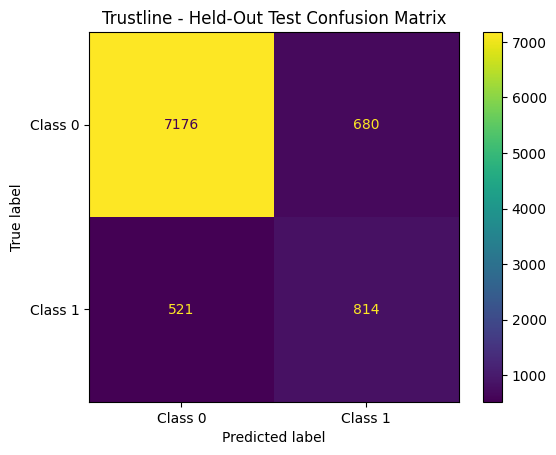

In [61]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import torch

# Scale test data using the scaler fitted on training data
X_test_final_scaled = final_scaler.transform(X_test).astype(np.float32)

X_test_final_tensor = torch.tensor(
    X_test_final_scaled,
    dtype=torch.float32,
    device=device
)

# Evaluate the selected model
final_model.eval()
with torch.no_grad():
    logits = final_model(X_test_final_tensor)
    positive_probabilities = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()

# Apply the threshold selected during validation
FINAL_THRESHOLD = 0.50
test_predictions = (
    positive_probabilities >= FINAL_THRESHOLD
).astype(int)

# Calculate final test metrics
test_accuracy = accuracy_score(y_test, test_predictions)
test_precision = precision_score(y_test, test_predictions, zero_division=0)
test_recall = recall_score(y_test, test_predictions, zero_division=0)
test_f1 = f1_score(y_test, test_predictions, zero_division=0)
test_cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])

print("FINAL HELD-OUT TEST RESULTS")
print("=" * 35)
print(f"Test samples: {len(y_test)}")
print(f"Threshold: {FINAL_THRESHOLD:.2f}")
print(f"Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Precision: {test_precision * 100:.2f}%")
print(f"Recall:    {test_recall * 100:.2f}%")
print(f"F1-score:  {test_f1 * 100:.2f}%")
print("\nConfusion Matrix:")
print(test_cm)
print("\nClassification Report:")
print(classification_report(y_test, test_predictions, zero_division=0))

ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["Class 0", "Class 1"]
).plot()
plt.title("Trustline - Held-Out Test Confusion Matrix")
plt.show()

### Final Test Results and Interpretation

The selected Trustline MLP model was evaluated on the original held-out test split containing 9,191 samples. The model used mild class weights and a decision threshold of 0.50.

**Final test metrics:**

- Accuracy: 86.93%
- Precision: 54.48%
- Recall: 60.97%
- F1-score: 57.55%

The confusion matrix shows that the model correctly classified 7,176 class 0 samples and 814 class 1 samples. It incorrectly classified 680 class 0 samples as class 1 and missed 521 class 1 samples.

The model achieves 86.93% overall accuracy and identifies approximately 61% of the actual class 1 samples. Precision of 54.48% indicates that some samples predicted as class 1 are actually class 0.

These results describe performance on the YelpChi dataset. They should not be interpreted as proof of equivalent performance on real-world e-commerce seller fraud.

# Final Model Selection and Evaluation

## 1. Objective

After conducting eight experiments on the YelpChi dataset, the objective was to identify a suitable neural network configuration for the Trustline classification component.

Different configurations were evaluated to understand how architecture, dropout, normalization, optimizer choice, learning-rate scheduling, class weighting, and decision thresholds affect classification performance.

The experiments were compared using validation metrics, with particular emphasis on the F1-score because the dataset contains an imbalanced distribution of class labels.

## 2. Experimental Setup

The YelpChi dataset was represented using 32 numerical features and two class labels.

The dataset was divided into training and testing sets using an 80:20 stratified split with `random_state=42`.

| Dataset partition | Number of samples |
|---|---:|
| Original training split | 36,763 |
| Original held-out test split | 9,191 |
| Total | 45,954 |

The original training split was further divided into a training subset and a validation subset for the controlled experiments.

| Validation setup | Number of samples |
|---|---:|
| Subtraining set | 31,248 |
| Validation set | 5,515 |

The common validation set contained 4,714 class 0 samples and 801 class 1 samples.

The validation set was used to compare the experimental configurations. The original test split was subsequently used to evaluate the selected configuration.

## 3. Evaluation Metrics

The following metrics were used to compare model performance.

- **Accuracy:** The proportion of all samples classified correctly.
- **Precision:** The proportion of samples predicted as class 1 that actually belong to class 1.
- **Recall:** The proportion of actual class 1 samples correctly identified by the model.
- **F1-score:** The harmonic mean of precision and recall. It is useful when both false positives and false negatives matter.
- **Confusion matrix:** A table showing correct and incorrect predictions for each class.

The F1-score was used as the primary selection metric because accuracy alone can be misleading when one class is much more common than the other.

## 4. Summary of the Eight Experiments

The eight experiments investigated different aspects of the neural network and its classification behavior.

| Approach | Experiment | Main finding |
|---|---|---|
| 1 | Smaller learning rate and more epochs | The recorded validation F1-score was 50.99%. |
| 2 | Larger MLP architecture | The recorded validation F1-score was 52.32%. |
| 3 | Dropout tuning | Dropout rates of (0.1, 0.1, 0.1) achieved an F1-score of 54.48%. |
| 4 | Batch Normalization | The low-dropout baseline outperformed the Batch Normalization variant on F1-score. |
| 5 | Adam versus AdamW | Adam achieved an F1-score of 54.48% in this comparison. |
| 6 | Learning-rate scheduler | Constant learning rate performed better on F1-score than the tested StepLR schedule. |
| 7 | Class-weight tuning | Mild class weights achieved the highest recorded validation F1-score of 59.55%. |
| 8 | Decision-threshold tuning | Threshold 0.50 achieved an F1-score of 59.55%, matching the best result from Approach 7. |

The results for Approaches 3–8 were obtained using the common validation setup. The earlier approaches were also recorded in the consolidated comparison, but their original experimental history included earlier evaluations; their results should therefore be interpreted with that limitation in mind.

## 5. Selection of the Final Configuration

### 5.1 Class-weight tuning

The dataset contains substantially more class 0 samples than class 1 samples. Class weighting was investigated to reduce the effect of this imbalance during training.

Three weighting strategies were compared:

- No class weights
- Mild class weights
- Balanced class weights

Mild class weights achieved the highest validation F1-score among these configurations.

The mild weights used in the validation experiment were approximately:

- Class 0: 0.7649
- Class 1: 1.8549

This configuration achieved a validation accuracy of 88.32%, precision of 59.92%, recall of 59.18%, and F1-score of 59.55%.

### 5.2 Decision-threshold tuning

The classifier produces probabilities for the two classes. A decision threshold determines when a sample is assigned to class 1.

Thresholds of 0.30, 0.40, 0.50, 0.60, and 0.70 were evaluated using the same validation set.

Threshold 0.50 achieved the highest validation F1-score of 59.55%.

Lower thresholds increased recall but also produced more false positives. Higher thresholds increased precision but missed more class 1 samples.

Since threshold 0.50 achieved the best F1-score among the tested thresholds, it was retained for the final evaluation.

### 5.3 Selected model configuration

The selected configuration was:

| Parameter | Selected value |
|---|---|
| Model | Multilayer Perceptron (MLP) |
| Input features | 32 |
| Hidden layers | 128, 64, 32 neurons |
| Activation | ReLU |
| Dropout | 0.1 after each hidden layer |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Training epochs | 20 |
| Batch size | 256 |
| Loss function | Weighted cross-entropy |
| Class weighting | Mild class weights |
| Decision threshold | 0.50 |

This configuration was selected based on the highest recorded validation F1-score. Threshold tuning did not increase the best F1-score beyond the result obtained through class-weight tuning.

## 6. Training the Selected Model

After selecting the configuration, the model was trained on the full original training split of 36,763 samples.

The standardization scaler was fitted on the training features and then applied to the test features. This prevents the scaler from learning information from the test set.

Mild class weights were calculated from the original training labels, and the selected MLP was trained for 20 epochs using Adam with a learning rate of 0.001.

The training loss decreased from 0.5265 in the first epoch to 0.3451 in the twentieth epoch.

This decrease indicates that the model's training loss improved during optimization. However, training loss alone does not establish how well the model generalizes; the test metrics provide additional evidence of its performance.

## 7. Final Held-Out Test Evaluation

The trained model was evaluated on the original test split containing 9,191 samples. The decision threshold was fixed at 0.50, as selected during validation.

The final recorded results were:

| Metric | Final test result |
|---|---:|
| Accuracy | 86.93% |
| Precision | 54.48% |
| Recall | 60.97% |
| F1-score | 57.55% |

These values represent the final evaluation of the selected configuration on the test split.

The validation F1-score was 59.55%, while the final test F1-score was 57.55%. The difference indicates that the model's measured performance varies between the validation and test samples.

## 8. Confusion Matrix Analysis

The confusion matrix for the final test evaluation was:

| Actual class | Predicted class 0 | Predicted class 1 |
|---|---:|---:|
| Class 0 | 7,176 | 680 |
| Class 1 | 521 | 814 |

The matrix can be interpreted as follows:

- **7,176 true class 0 predictions:** The model correctly classified these class 0 samples.
- **680 false positive predictions:** These class 0 samples were incorrectly predicted as class 1.
- **521 false negative predictions:** These class 1 samples were incorrectly predicted as class 0.
- **814 true class 1 predictions:** The model correctly identified these class 1 samples.

The recall of 60.97% means that the model identified 814 of the 1,335 actual class 1 samples.

The precision of 54.48% indicates that a considerable proportion of the samples predicted as class 1 were actually class 0. Therefore, the model still produces false positive predictions and misses some class 1 samples.

## 9. Overall Conclusion

Eight experimental approaches were investigated to identify a suitable MLP configuration. Based on the recorded common-validation results, mild class weighting achieved the highest F1-score of 59.55%. Threshold 0.50 retained that same F1-score and was selected for the final configuration.

The selected model was trained on the full original training split and evaluated on the 9,191-sample test split. It achieved 86.93% accuracy, 54.48% precision, 60.97% recall, and a 57.55% F1-score.

These results provide a quantitative evaluation of the selected classifier on the YelpChi dataset. The test split had also been examined during earlier exploratory experiments, so the final results should not be described as coming from a test set that remained completely untouched throughout the project.

## 10. Dataset and Scope Limitation

YelpChi is a dataset associated with Yelp reviews and suspicious reviewing behavior. It is not a directly verified dataset of fraudulent e-commerce sellers.

Consequently, the reported metrics demonstrate classification performance on the YelpChi labels. They do not establish equivalent accuracy for detecting counterfeit products, fraudulent online sellers, or deceptive e-commerce listings.

Further evaluation using suitable e-commerce seller data would be required before making those real-world performance claims.

## Step 4: Save the Final Selected Model and Scaler

After completing the final test evaluation, we save the selected Trustline model and its corresponding feature scaler.

The trained model contains the learned neural network weights, while the scaler stores the parameters required to standardize input features consistently during prediction.

Both files are saved so that the trained model can be loaded later by the FastAPI backend without training the model again.

### Files saved

- **`trustline_selected_mlp.pth`** — stores the trained weights of the selected Multilayer Perceptron (MLP).
- **`trustline_selected_scaler.pkl`** — stores the fitted `StandardScaler` used to transform the input features.

### Why is this step important?

The backend must use the same trained model and matching scaler used during evaluation. Applying a different scaler or changing the feature order could produce incorrect predictions.

After saving, we verify that both files exist in the output directory. These artifacts will be used in the next stage to integrate the model with the Trustline backend.

**Note:** Saving the model does not retrain it or change the evaluation results.

In [62]:
import os
import torch
import joblib

os.makedirs("/kaggle/working/models", exist_ok=True)

torch.save(
    final_model.state_dict(),
    "/kaggle/working/models/trustline_selected_mlp.pth"
)

joblib.dump(
    final_scaler,
    "/kaggle/working/models/trustline_selected_scaler.pkl"
)

print("Model and scaler saved successfully.")
print(os.listdir("/kaggle/working/models"))

Model and scaler saved successfully.
['trustline_selected_scaler.pkl', 'trustline_selected_mlp.pth', 'trustline_yelpchi_mlp.pth']


## Step 5: Export the Final Model for the Streamlit App

In this step, we export the final selected Trustline model and its corresponding scaler in the format required by the Streamlit application.

The exported files include the trained model, scaler, evaluation metrics, and representative test samples. These files allow the application to load the trained model without retraining it.

We also verify the exported model against the final held-out test results to ensure that the exported artifacts are consistent with the notebook's evaluation.

In [63]:

import os
import json
import joblib
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Paths created by Step 4
SRC_MODEL = "/kaggle/working/models/trustline_selected_mlp.pth"
SRC_SCALER = "/kaggle/working/models/trustline_selected_scaler.pkl"
OUT = "/kaggle/working/export"

os.makedirs(OUT, exist_ok=True)

# Load the final selected model weights
raw = torch.load(SRC_MODEL, map_location="cpu", weights_only=True)

# Convert layer names to the format expected by model_service.py
sd = {k.replace("network.", "", 1): v for k, v in raw.items()}

# Reconstruct the selected model architecture
net = nn.Sequential(
    nn.Linear(32, 128), nn.ReLU(), nn.Dropout(0.1),
    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.1),
    nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.1),
    nn.Linear(32, 2)
)

net.load_state_dict(sd)
net.eval()

# Load the matching scaler
scaler = joblib.load(SRC_SCALER)

# Use the existing held-out test data from the notebook
X_arr = np.asarray(X_test, dtype=np.float32)
y_arr = np.asarray(y_test)

# Evaluate the exported model
with torch.no_grad():
    X_scaled = scaler.transform(X_arr)
    probs = torch.softmax(
        net(torch.tensor(X_scaled, dtype=torch.float32)),
        dim=1
    ).numpy()

pred = (probs[:, 1] >= 0.50).astype(int)
cm = confusion_matrix(y_arr, pred, labels=[0, 1])

metrics = {
    "model": "Selected MLP 32-128-64-32-2, dropout 0.1, threshold 0.50",
    "n_test": int(len(y_arr)),
    "accuracy": float(accuracy_score(y_arr, pred)),
    "precision": float(precision_score(y_arr, pred, zero_division=0)),
    "recall": float(recall_score(y_arr, pred, zero_division=0)),
    "f1": float(f1_score(y_arr, pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_arr, probs[:, 1])),
    "pr_auc": float(average_precision_score(y_arr, probs[:, 1])),
    "confusion_matrix": cm.tolist()
}

# Select representative samples from both classes
rng = np.random.default_rng(42)
idx = np.concatenate([
    rng.choice(np.where(y_arr == c)[0], 8, replace=False)
    for c in (0, 1)
])

samples = [
    {
        "id": n + 1,
        "test_index": int(k),
        "true_label": int(y_arr[k]),
        "features": [float(v) for v in X_arr[k]]
    }
    for n, k in enumerate(idx)
]

# Export the model and scaler using the application's expected filenames
torch.save(sd, f"{OUT}/trustline_model.pth")
joblib.dump(scaler, f"{OUT}/trustline_scaler.pkl")

# Export evaluation metrics and sample data
with open(f"{OUT}/model_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

with open(f"{OUT}/demo_samples.json", "w", encoding="utf-8") as f:
    json.dump(samples, f, indent=2)

# Export the eight-experiment comparison if available
if "comparison_data" in globals():
    with open(f"{OUT}/experiments.json", "w", encoding="utf-8") as f:
        json.dump(comparison_data, f, indent=2)

print("Exported model metrics:")
print([
    round(metrics[k] * 100, 2)
    for k in ("accuracy", "precision", "recall", "f1")
])

print("Confusion matrix:")
print(cm.tolist())

print(
    "Matches notebook final result:",
    cm.tolist() == [[7176, 680], [521, 814]]
)

print("Exported files:")
print(sorted(os.listdir(OUT)))


Exported model metrics:
[86.93, 54.48, 60.97, 57.55]
Confusion matrix:
[[7176, 680], [521, 814]]
Matches notebook final result: True
Exported files:
['demo_samples.json', 'experiments.json', 'model_metrics.json', 'trustline_model.pth', 'trustline_scaler.pkl']
